**15.071 The AI Edge** · Project 1 · Fall 2026

---

# Retail Demand Analytics: Predicting Walmart Item Sales
## Final Model on All 30,490 Item-Store Series: Recent Sales, Item × Store Effects and the WRMSSE Metric

### Background

Retailers decide every day how much of each product to stock in each store. Ordering too little loses sales and frustrates customers; ordering too much ties up working capital and, for perishable goods, ends in waste. A model that predicts how many units of an item will sell on a given day, in a given store, is the starting point for inventory planning, promotions and pricing.

In this project we use the **M5 Walmart dataset** to build regression models that predict the **daily unit sales of an item in a store** from its price, its product category, the store, the calendar (month and weekday), special events (holidays, sporting and cultural events) and SNAP days, which are the days on which US food-assistance (SNAP) benefits are paid out in California, Texas and Wisconsin.

Following the approach of Lecture 4, we begin with ordinary least squares (OLS) regression, then introduce **Ridge regression** and **LASSO**, use **10-fold cross-validation** to select the amount of regularization, and compare the three models on a held-out test set.

**Starting point and what we add.** The original model used only the 10 requested features (`sell_price`, `cat_id`, `store_id`, `event_name`, `event_type`, `snap_CA`, `snap_TX`, `snap_WI`, `month`, `weekday`) on all items and explained only about **5%** of the variation in daily sales (test OSR² 0.046): those features describe the day and the place, but not which product is sold or how well it has been selling. This notebook keeps the same 80/20 pipeline, now split **in time** (training on the first 80% of the days, testing on the last 20%), and makes the following changes:

1. **All item-store series**: unlike the Final notebook, which kept only the 6,638 regular sellers, we keep all **30,490** series, including slow and intermittent sellers.
2. **`item_id`** and **`item_store`** (item × store), one-hot encoded: each item, and each item in each store, gets its own baseline level of sales.
3. **`roll28`** and **`roll7`**: the **average daily sales of the same item-store over the previous 28 and 7 days**. They track how well the item is selling *right now*; the 28-day average is stable, the 7-day average reacts quickly to promotions, stock-outs or changes in trend. Both only use days **before** the day being predicted, so no information from the future leaks into the model.
4. **A time-based training/test split**: the models are trained on days `d_1` to `d_1552` (up to 2015-04-29) and tested on the last 389 days, `d_1553` to `d_1941`, the same split as the TimesFM notebooks. The test set therefore measures how well the model predicts days that come **after** everything it was trained on, as a real forecast must.
5. **WRMSSE** (Weighted Root Mean Squared Scaled Error), the official accuracy measure of the M5 forecasting competition, reported next to R², OSR² and RMSE. Unlike RMSE, it scales each item-store's error by how hard that item-store is to forecast and weights item-stores by their dollar sales, so a model is rewarded for getting the products that matter to the business right.


> **Run note.** This copy of the all-30,490-series notebook runs on the MIT ORCD Engaging cluster. The Ridge path, both 10-fold cross-validations and the feature ablation are spread over the job's CPU cores with `joblib`. The models, data, λ grids, folds and random seeds are the same as in the serial version, so the results are the same; only the run time changes. On 32 cores the whole notebook ran in 35 minutes.

We start by locating the data files and importing the Python packages used throughout this notebook.

In [1]:
import os

# DATA_DIR is the folder that holds the three M5 csv files. We look in the
# notebook's own folder first, then in its parent folder. If you have moved the
# notebook or the data, set it by hand instead, for example:
#     DATA_DIR = '/path/to/m5/data'
DATA_FILES = ('sales_train_evaluation.csv', 'calendar.csv', 'sell_prices.csv')
DATA_DIR = None
for candidate in (os.getcwd(), os.path.dirname(os.getcwd())):
    if all(os.path.isfile(os.path.join(candidate, f)) for f in DATA_FILES):
        DATA_DIR = candidate
        break
if DATA_DIR is None:
    raise RuntimeError('Data files not found: set DATA_DIR by hand above.')

print('Data directory:', DATA_DIR)

Data directory: ~/m5_all30490


In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt
import seaborn as sns

# Parallel execution on the MIT ORCD cluster: use every core SLURM gave this job
from joblib import Parallel, delayed
N_JOBS = int(os.environ.get('SLURM_CPUS_PER_TASK', os.cpu_count()))
print(f'Parallel workers: {N_JOBS}')


Parallel workers: 32


## The M5 Walmart Dataset

The data come in three files that must be joined together:

| File | Content | Key columns |
|---|---|---|
| `sales_train_evaluation.csv` | Daily unit sales of 3,049 items in 10 stores (30,490 item-store series) over 1,941 days, in **wide** format: one column per day `d_1` … `d_1941` | `item_id`, `cat_id`, `store_id`, `d_*` |
| `calendar.csv` | One row per day: date, weekday, month, events and SNAP indicators | `d`, `wm_yr_wk` |
| `sell_prices.csv` | Weekly selling price of each item in each store | `store_id`, `item_id`, `wm_yr_wk` |

- **Industry**: Retail (Walmart, US)
- **Unit of observation**: one item, in one store, on one day
- **Target variable**: `sales`, the number of units sold that day
- **Feature variables**: `sell_price`, `roll28`, `roll7`, `item_id`, `item_store`, `cat_id`, `store_id`, `event_name`, `event_type`, `snap_CA`, `snap_TX`, `snap_WI`, `month`, `weekday`

### Loading and Inspecting the Data

In [3]:
sales_wide = pd.read_csv(os.path.join(DATA_DIR, 'sales_train_evaluation.csv'))
calendar   = pd.read_csv(os.path.join(DATA_DIR, 'calendar.csv'))
prices     = pd.read_csv(os.path.join(DATA_DIR, 'sell_prices.csv'))

d_cols = [c for c in sales_wide.columns if c.startswith('d_')]

print(f"Sales:    {sales_wide.shape[0]:,} item-store series x {len(d_cols):,} days "
      f"= {sales_wide.shape[0] * len(d_cols):,} item-store-days")
print(f"Calendar: {calendar.shape[0]:,} days")
print(f"Prices:   {prices.shape[0]:,} item-store-week prices")

display(sales_wide.iloc[:5, :10])
display(calendar.head())
display(prices.head())

Sales:    30,490 item-store series x 1,941 days = 59,181,090 item-store-days
Calendar: 1,969 days
Prices:   6,841,121 item-store-week prices


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


### Keeping Every Item-Store Series

The Final notebook kept only the 6,638 item-store series that sold on more than 50% of the 1,941 days. Here we keep **all 30,490 series**, including the slow and intermittent sellers, so the model is trained and tested on the full M5 assortment.

We still compute each series' share of days with positive sales, to show how many of the series are intermittent, but nothing is filtered on it. The rest of the notebook is unchanged.

Series kept: 30,490 of 30,490 (100%)
Series that sold on more than 50% of days (the Final notebook's filter): 6,638 (21.8%)


,Series,Median share of days with a sale
cat_id,,
FOODS,14370,0.350
HOBBIES,5650,0.170
HOUSEHOLD,10470,0.227


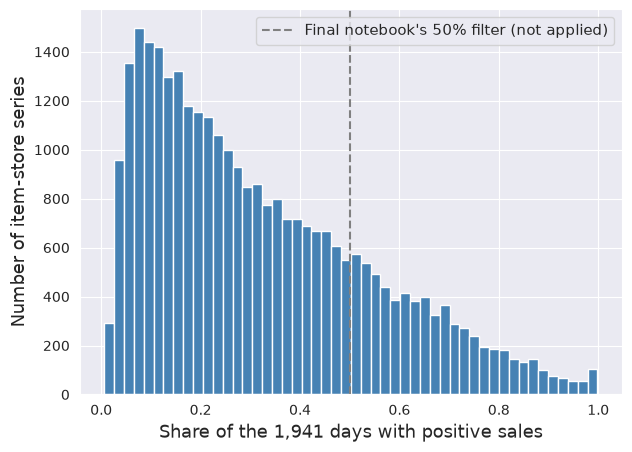

In [4]:
# Share of the 1,941 days on which each series sold at least one unit (description only, no filter)
selling_share = (sales_wide[d_cols] > 0).mean(axis=1)

print(f"Series kept: {len(sales_wide):,} of {len(sales_wide):,} (100%)")
print(f"Series that sold on more than 50% of days (the Final notebook's filter): "
      f"{(selling_share > 0.5).sum():,} ({(selling_share > 0.5).mean():.1%})")

by_cat = pd.DataFrame({
    'Series': sales_wide['cat_id'].value_counts(),
    'Median share of days with a sale': selling_share.groupby(sales_wide['cat_id']).median().round(3),
})
display(by_cat)

sns.set_style("darkgrid")
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(selling_share, bins=50, color='steelblue')
ax.axvline(0.5, linestyle='--', color='grey', linewidth=1.5, label="Final notebook's 50% filter (not applied)")
ax.set_xlabel('Share of the 1,941 days with positive sales', fontsize=13)
ax.set_ylabel('Number of item-store series', fontsize=13)
ax.legend(fontsize=11)
plt.show()

### Building the Modeling Dataset

Stacking the sales file into one row per item, store and day would give about **59 million rows**. Fitting thousands of Ridge and LASSO models during cross-validation on 59 million rows would take days. We therefore draw a **random sample of item-store-days**, separately from the **training period** and from the **test period**:

| Period | Days | Dates | Observations kept |
|---|---|---|---|
| Training | `d_1` to `d_1552` (first 80% of the 1,941 days) | 2011-01-29 to 2015-04-29 | 80,000 |
| Test | `d_1553` to `d_1941` (last 20%, 389 days) | 2015-04-30 to 2016-05-22 | 20,000 |

This is the same split as in the TimesFM notebooks. Within each period:

1. Pick random (item-store series, day) cells from the wide sales table and read off the units sold. Training days are drawn from day 29 onward, so that every observation has 28 days of history.
2. Compute **`roll28`** and **`roll7`**, the average daily sales of the same series over the 28 days and over the 7 days **before** the drawn day. We also record the sales of the day before (`lag1`), **not as a feature** but to build the naive "same as yesterday" benchmark used by WRMSSE below.
3. Join the **calendar** on the day `d` to get the weekday, month, events, SNAP flags and the Walmart week `wm_yr_wk`.
4. Join the **prices** on store, item and week to get `sell_price`.
5. Drop the cells with no price. An item has no price in the weeks before it was first stocked in that store, so those zeros are not real "no sale" days. Keeping them would teach the model that an unlisted item sells nothing, which is true but useless.
6. Keep **80,000** training and **20,000** test observations.

We use a random seed so that the sample, and every result below, is reproducible.

**What the model knows when it predicts a test day.** The coefficients are estimated on the training period only and are never updated. `roll28` and `roll7` are computed from the sales of the days just before the predicted day, so for a test day in, say, March 2016 they use the sales of February and March 2016, which a store manager would know the evening before. Each prediction is therefore a **one-day-ahead** forecast made by a model frozen on 2015-04-29.

In [5]:
np.random.seed(71)

N_TRAIN_DAYS = int(0.8 * len(d_cols))   # 1,552: d_1 to d_1552 is the training period
N_TRAIN, N_TEST = 80_000, 20_000        # observations kept in each period
N_DRAW_TRAIN, N_DRAW_TEST = 130_000, 30_000   # cells drawn before dropping the ones with no price
HISTORY = 28          # days of history used for roll28
HISTORY_SHORT = 7     # days of history used for roll7

# Step 1: draw random (series, day) cells in each period; training days leave 28 days of history
row_idx = np.r_[np.random.randint(0, len(sales_wide), N_DRAW_TRAIN),
                np.random.randint(0, len(sales_wide), N_DRAW_TEST)]
day_idx = np.r_[np.random.randint(HISTORY, N_TRAIN_DAYS, N_DRAW_TRAIN),
                np.random.randint(N_TRAIN_DAYS, len(d_cols), N_DRAW_TEST)]

units = sales_wide[d_cols].to_numpy().astype(float)

df = sales_wide.iloc[row_idx][['id', 'item_id', 'cat_id', 'store_id']].reset_index(drop=True)
df['d'] = np.array(d_cols)[day_idx]
df['period'] = np.where(day_idx < N_TRAIN_DAYS, 'train', 'test')
df['sales'] = units[row_idx, day_idx]

# Step 2: average daily sales over the 28 and 7 days BEFORE the drawn day.
# A running total along each row turns every 28-day sum into one subtraction.
cum_units = np.hstack([np.zeros((len(units), 1)), np.cumsum(units, axis=1)])
df['roll28'] = (cum_units[row_idx, day_idx] - cum_units[row_idx, day_idx - HISTORY]) / HISTORY

# Average daily sales over the 7 days BEFORE the drawn day
df['roll7'] = (cum_units[row_idx, day_idx] - cum_units[row_idx, day_idx - HISTORY_SHORT]) / HISTORY_SHORT

# Sales on the previous day: NOT a feature, only used for the naive benchmark
df['lag1'] = units[row_idx, day_idx - 1]

# Steps 3 and 4: join the calendar and the prices
df = df.merge(calendar, on='d', how='left')
df = df.merge(prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')

# Step 5: drop the cells where the item was not yet on sale
print("Cells drawn and share without a price:")
print(df.groupby('period', sort=False)['sell_price'].agg(drawn='size', no_price=lambda s: s.isna().mean())
        .to_string(formatters={'drawn': '{:,}'.format, 'no_price': '{:.1%}'.format}))
df = df.dropna(subset=['sell_price'])

# Step 6: keep N_TRAIN training and N_TEST test observations (training rows first)
df = pd.concat([df[df['period'] == 'train'].sample(n=N_TRAIN, random_state=71),
                df[df['period'] == 'test'].sample(n=N_TEST, random_state=71)]).reset_index(drop=True)

# The item x store label, e.g. FOODS_3_090_CA_3
df['item_store'] = df['item_id'] + '_' + df['store_id']

print(f"\nObservations kept: {len(df):,}")
for p in ['train', 'test']:
    sub = df[df['period'] == p]
    print(f"  {p:<5}: {len(sub):>6,} observations, {sub['date'].min()} to {sub['date'].max()}")

Cells drawn and share without a price:
         drawn no_price
period                 
train  130,000    25.3%
test    30,000     0.3%

Observations kept: 100,000
  train: 80,000 observations, 2011-02-26 to 2015-04-29
  test : 20,000 observations, 2015-04-30 to 2016-05-22


### Preparing the Event Variables

The calendar records up to two events per day (`event_name_1`, `event_type_1`, `event_name_2`, `event_type_2`). A second event occurs on only a handful of days (Easter, Cinco De Mayo, Orthodox Easter and Father's Day coinciding with another event), so we use the **first event** as `event_name` and `event_type`. Days with no event are labeled `No_Event`, which will serve as the baseline category.

In [6]:
df['event_name'] = df['event_name_1'].fillna('No_Event')
df['event_type'] = df['event_type_1'].fillna('No_Event')

print(f"Days with a second event in the calendar: {calendar['event_name_2'].notna().sum()}")
print("\nShare of sampled observations by event type:")
print(df['event_type'].value_counts(normalize=True).round(4).to_string())

display(df[['item_store', 'date', 'sales', 'roll28', 'roll7', 'sell_price', 'cat_id', 'store_id', 'event_name',
            'event_type', 'snap_CA', 'snap_TX', 'snap_WI', 'month', 'weekday']].head(10))

Days with a second event in the calendar: 5

Share of sampled observations by event type:
event_type
No_Event     0.9196
Religious    0.0280
National     0.0263
Cultural     0.0183
Sporting     0.0079


,item_store,date,sales,roll28,roll7,sell_price,cat_id,store_id,event_name,event_type,snap_CA,snap_TX,snap_WI,month,weekday
0,HOUSEHOLD_2_229_CA_1,2013-11-30,1.0,0.000000,0.000000,4.43,HOUSEHOLD,CA_1,No_Event,No_Event,0,0,0,11,Saturday
1,HOUSEHOLD_2_195_WI_3,2014-03-16,0.0,0.107143,0.142857,14.97,HOUSEHOLD,WI_3,Purim End,Religious,0,0,0,3,Sunday
2,HOUSEHOLD_2_052_TX_3,2012-07-05,0.0,0.000000,0.000000,4.97,HOUSEHOLD,TX_3,No_Event,No_Event,1,1,1,7,Thursday
3,HOUSEHOLD_1_540_CA_4,2015-03-07,3.0,1.750000,1.285714,1.64,HOUSEHOLD,CA_4,No_Event,No_Event,1,1,0,3,Saturday
4,HOUSEHOLD_1_181_CA_2,2013-11-20,1.0,1.321429,0.857143,3.98,HOUSEHOLD,CA_2,No_Event,No_Event,0,0,0,11,Wednesday
5,FOODS_1_017_TX_3,2012-06-09,2.0,0.035714,0.000000,2.68,FOODS,TX_3,No_Event,No_Event,1,1,1,6,Saturday
6,FOODS_1_011_WI_1,2012-05-13,2.0,1.000000,1.571429,2.48,FOODS,WI_1,Mother's day,Cultural,0,1,0,5,Sunday
7,FOODS_2_319_CA_1,2013-07-14,0.0,0.607143,0.285714,2.82,FOODS,CA_1,No_Event,No_Event,0,0,1,7,Sunday
8,HOBBIES_1_047_CA_4,2015-04-06,0.0,0.642857,0.571429,1.77,HOBBIES,CA_4,No_Event,No_Event,1,1,1,4,Monday
9,FOODS_3_702_CA_2,2012-05-14,6.0,2.142857,2.857143,2.98,FOODS,CA_2,No_Event,No_Event,0,0,1,5,Monday


### One-Hot Encoding the Categorical Features

Apart from `sell_price`, every feature is **categorical**: its values are labels, not quantities. Month 12 is not "twelve times" month 1, and store `WI_3` is not larger than store `CA_1`. If we fed these labels into a regression as numbers, the model would be forced to fit a straight line across them, which makes no sense.

**One-hot encoding** solves this by creating one 0/1 indicator column for each level of a categorical variable. For each variable we then **drop one level, the baseline**, because the indicators of all levels always add up to one and would otherwise be perfectly collinear with the intercept (the "dummy variable trap"). Each remaining coefficient measures the difference in expected sales between that level and the baseline, holding everything else fixed.

We choose interpretable baselines: `FOODS`, store `CA_1`, `No_Event`, non-SNAP days (`0`), January and Monday. For `item_id`, which has over a thousand levels and no natural reference, the baseline is simply the first item in alphabetical order. Each item coefficient then measures how many more (or fewer) units that item sells per day than the baseline item, holding price, store and calendar fixed.

For `item_store` the baseline is likewise the first item-store in alphabetical order.

`item_store` is by far the largest categorical variable, with over 28,000 levels. A regular (dense) matrix of 100,000 rows by about 31,500 columns would need about 25 GB of memory, although almost every entry is zero: each row has a single 1 among the `item_store` columns, a single 1 among the `item_id` columns, and so on. We therefore build the one-hot columns with sklearn's `OneHotEncoder`, which returns a **sparse matrix** storing only the nonzero entries (about 0.9 million numbers instead of 3.2 billion). sklearn's linear models accept sparse matrices directly.

In [7]:
cat_features = ['item_store', 'item_id', 'cat_id', 'store_id', 'event_name', 'event_type',
                'snap_CA', 'snap_TX', 'snap_WI', 'month', 'weekday']
num_features = ['sell_price', 'roll28', 'roll7']

baselines = {
    'cat_id': 'FOODS', 'store_id': 'CA_1',
    'event_name': 'No_Event', 'event_type': 'No_Event',
    'snap_CA': '0', 'snap_TX': '0', 'snap_WI': '0',
    'month': '1', 'weekday': 'Monday',
}
baselines['item_id'] = sorted(df['item_id'].unique())[0]
baselines['item_store'] = sorted(df['item_store'].unique())[0]
print(f"Baseline item: {baselines['item_id']} | baseline item-store: {baselines['item_store']}")

# One indicator column per level (levels in their natural order, so month 2
# comes before month 10), dropping the baseline level of each variable.
# The result is a sparse matrix.
cat_values = df[cat_features].astype(str)
categories = [[str(v) for v in sorted(df[c].unique())] for c in cat_features]
encoder = OneHotEncoder(categories=categories,
                        drop=[baselines[c] for c in cat_features],
                        sparse_output=True, dtype=float)
dummies = encoder.fit_transform(cat_values)
dummy_cols = encoder.get_feature_names_out(cat_features).tolist()

# Numeric features first, then the indicators
X = sp.hstack([sp.csr_matrix(df[num_features].to_numpy()), dummies]).tocsr()
y = df['sales'].astype(float)

n = len(df)
feature_cols = num_features + dummy_cols
k = len(feature_cols)

print(f"Observations: {n:,} | Features after one-hot encoding: {k:,}")
print(f"Nonzero entries: {X.nnz:,} of {n * k:,} ({X.nnz / (n * k):.3%})")
print("\nIndicator columns per variable (baseline dropped):")
for c in cat_features:
    print(f"  {c:<11} {sum(col.startswith(c + '_') for col in dummy_cols):>5,}")

Baseline item: FOODS_1_001 | baseline item-store: FOODS_1_001_CA_1


Observations: 100,000 | Features after one-hot encoding: 31,262
Nonzero entries: 898,603 of 3,126,200,000 (0.029%)

Indicator columns per variable (baseline dropped):
  item_store  28,146
  item_id     3,048
  cat_id          2
  store_id        9
  event_name     30
  event_type      4
  snap_CA         1
  snap_TX         1
  snap_WI         1
  month          11
  weekday         6


### Creating the Training and Test Sets

We split the observations **in time**, as in the TimesFM notebooks:

- **Training set**: the 80,000 observations from the first 80% of the days, `d_1` to `d_1552` (up to 2015-04-29). It is used to fit the models and, through cross-validation, to choose the amount of regularization.
- **Test set**: the 20,000 observations from the last 20% of the days, `d_1553` to `d_1941` (2015-04-30 to 2016-05-22, 389 days). It is kept aside to measure how well each model predicts days that come **after** all the training data.

A random split would mix training and test days from the same months, so the model would effectively "fill in gaps" between days it has already seen. The time split is harder and more honest: prices, trends and the product range drift over time, and some items are launched only during the test period, so the test set contains item-stores the model has never seen.

Note on the one-hot columns: the encoder above lists every level that occurs in the sample, including the few item-stores that occur only in the test period. Their columns are all zero in the training set, so their coefficients are zero (OLS, Ridge and LASSO all leave a column with no variation at zero), and these test rows are predicted from the item, category, store, price, calendar and recent-sales features alone. No test sales are used.

In [8]:
# Time split: training rows come from d_1..d_1552, test rows from d_1553..d_1941
train_idx = np.flatnonzero(df['period'] == 'train')
test_idx = np.flatnonzero(df['period'] == 'test')

# Rows of a sparse matrix are selected with [ ], not .iloc
X_train = X[train_idx]
X_test  = X[test_idx]

y_train = y.iloc[train_idx]
y_test  = y.iloc[test_idx]

# Item-store series of each observation, used by WRMSSE
ids_train = df['id'].iloc[train_idx]
ids_test  = df['id'].iloc[test_idx]

n_train, k = X_train.shape

print(f"Observations: {n:,} | Features: {k:,} | Train: {n_train:,} | Test: {len(test_idx):,}")
print(f"Training days: {df['date'].iloc[train_idx].min()} to {df['date'].iloc[train_idx].max()} | "
      f"Test days: {df['date'].iloc[test_idx].min()} to {df['date'].iloc[test_idx].max()}")
print(f"Item-stores in the test set that also appear in training: "
      f"{df['item_store'].iloc[test_idx].isin(df['item_store'].iloc[train_idx]).mean():.1%}")
print(f"Average training observations per item-store: "
      f"{n_train / df['item_store'].iloc[train_idx].nunique():.1f}")
print(f"Mean daily sales: training {y_train.mean():.3f} | test {y_test.mean():.3f}")

Observations: 100,000 | Features: 31,262 | Train: 80,000 | Test: 20,000
Training days: 2011-02-26 to 2015-04-29 | Test days: 2015-04-30 to 2016-05-22
Item-stores in the test set that also appear in training: 86.2%
Average training observations per item-store: 3.1
Mean daily sales: training 1.457 | test 1.285


### Defining Performance Metrics

We use the same three performance measures as in Lecture 4, and add a fourth.

- **R² (Coefficient of Determination):** how well the model explains the variation in the **training data**.
- **OSR² (Out-of-Sample R²):** how well the model predicts the **test data**, relative to a simple benchmark that always predicts the average sales in the training set.
- **RMSE (Root Mean Squared Error):** the typical prediction error, in units sold per item per day.
- **WRMSSE (Weighted Root Mean Squared Scaled Error):** the accuracy measure of the M5 competition, described below. **Lower is better.**


In [9]:
def osr2(pred, y_test, y_train_mean):
    return 1 - np.sum((pred - y_test)**2) / np.sum((y_train_mean - y_test)**2)

def r2(pred, y_train):
    return 1 - np.sum((pred - y_train)**2) / np.sum((y_train - y_train.mean())**2)

def rmse(pred, y):
    return np.sqrt(np.mean((pred - y)**2))

def mae(pred, y):
    return np.mean(np.abs(np.asarray(pred) - np.asarray(y)))

def wape(pred, y):
    return np.sum(np.abs(np.asarray(pred) - np.asarray(y))) / np.sum(np.asarray(y))


### MAE and WAPE

Besides R², OSR², RMSE and WRMSSE we report two error measures that read directly in units sold:

- **MAE** (mean absolute error), $\frac{1}{n}\sum_t |y_t - \hat y_t|$: the typical miss, in units per item-store-day. Unlike RMSE it does not square the errors, so a few very large misses on the busiest days weigh less.
- **WAPE** (weighted absolute percentage error), $\sum_t |y_t - \hat y_t| \,/\, \sum_t y_t$: the total absolute error as a share of total units sold. It reads as "we miss by X% of volume" and, unlike the ordinary percentage error (MAPE), it is well defined on the many days with zero sales. It is widely used in retail.

Lower is better for both.

### The WRMSSE Metric

RMSE treats every unit of error the same, whatever the item. That has two drawbacks for a retailer. First, an error of 3 units is large for an item that usually sells 2 a day and small for one that sells 40, so RMSE is dominated by the high-volume items. Second, the business cares more about the items that bring in the most revenue. The M5 competition addresses both with the **WRMSSE**, which is built in three steps.

**1. Scale each series by how hard it is to forecast.** For each item-store series $i$, the scale $s_i$ is the mean squared error of the naive forecast "**tomorrow's sales equal today's**" over the series' history, starting from its first sale:

$$s_i = \frac{1}{T_i - 1} \sum_{t=2}^{T_i} \left( y_{i,t} - y_{i,t-1} \right)^2$$

**2. Compute each series' scaled error (RMSSE).** Over the $h_i$ test observations of series $i$:

$$\text{RMSSE}_i = \sqrt{ \frac{1}{h_i} \sum_{t \in \text{test}_i} \frac{\left( y_{i,t} - \hat{y}_{i,t} \right)^2}{s_i} }$$

An RMSSE of 1 means the model is about as accurate as the naive "same as yesterday" forecast; below 1 it is better.

**3. Weight the series by dollar sales.** The weight $w_i$ of each series is its share of total dollar sales (units sold × selling price), so

$$\text{WRMSSE} = \sum_i w_i \, \text{RMSSE}_i, \qquad \sum_i w_i = 1 .$$

**How our version differs from the M5 competition.** The competition forecasts the **next 28 days** of every series and averages the WRMSSE over 12 levels of aggregation (total, state, store, category, ..., item-store). Our test set is a **random sample of item-store-days** from the 389-day test period, so (a) we compute the WRMSSE at the **item-store level only**, because a random sample does not contain all the series of a given day and cannot be summed up into stores or states; (b) with 20,000 test observations spread over 30,490 series, most series have one or two test observations rather than 28, so a single series' RMSSE is very noisy, but the weighted average over the roughly 15,000 series in the test set is stable; (c) as in the competition, the scale and the weights use only the **training period**: the scale is computed from each series' first sale up to `d_1552`, and the weight is the series' dollar sales over the **last 28 training days** (`d_1525` to `d_1552`). Series with no sales in those 28 days, including items launched during the test period, get a weight of zero. Only the series that appear in the evaluated set count, with their weights renormalized to sum to one.


In [10]:
# WRMSSE uses only the training period (d_1 to d_1552), as in the M5 competition
train_units = units[:, :N_TRAIN_DAYS]

# Step 1: scale of each series = mean squared day-to-day change, from the first sale to d_1552
first_sale = (train_units > 0).argmax(axis=1)
day_changes = np.diff(train_units, axis=1)                 # y[t] - y[t-1]
active = np.arange(1, N_TRAIN_DAYS)[None, :] > first_sale[:, None]
n_active = active.sum(axis=1)
scale = np.where(active, day_changes**2, 0).sum(axis=1) / np.maximum(n_active, 1)
# No sale in the training period (or none before its last day): no scale
scale = np.where((train_units > 0).any(axis=1) & (n_active > 0), scale, np.nan)
series_scale = pd.Series(scale, index=sales_wide['id'])

# Step 3: weight of each series = dollar sales over the last 28 training days (d_1525 to d_1552)
week_of_day = calendar.set_index('d').loc[d_cols, 'wm_yr_wk'].to_numpy()
last28 = slice(N_TRAIN_DAYS - 28, N_TRAIN_DAYS)
price_wide = (prices.merge(sales_wide[['item_id', 'store_id']], on=['item_id', 'store_id'])
                    .pivot(index=['item_id', 'store_id'], columns='wm_yr_wk', values='sell_price')
                    .reindex(pd.MultiIndex.from_frame(sales_wide[['item_id', 'store_id']])))
price_daily = price_wide.reindex(columns=week_of_day[last28]).to_numpy()   # NaN = item not listed
series_revenue = pd.Series(np.nansum(units[:, last28] * price_daily, axis=1), index=sales_wide['id'])
# A series with a weight but no usable scale cannot be scored: give it zero weight
series_revenue[~(series_scale > 0)] = 0.0
del price_daily, day_changes, active, train_units


def wrmsse(pred, y_true, ids):
    """Item-store level WRMSSE of predictions `pred` for observations of series `ids`."""
    sq_err = pd.Series((np.asarray(pred) - np.asarray(y_true))**2, index=np.asarray(ids))
    mse = sq_err.groupby(level=0).mean()                    # Step 2: per-series MSE ...
    w = series_revenue.loc[mse.index]
    keep = w > 0                                            # series with zero weight do not count
    rmsse = np.sqrt(mse[keep] / series_scale.loc[mse.index[keep]])   # ... scaled, then square-rooted
    return float(np.sum(w[keep] * rmsse) / w[keep].sum())   # Step 3: dollar-weighted average


print(f"Scale s_i (mean squared daily change): median {series_scale.median():.2f}, "
      f"range {series_scale.min():.2f} to {series_scale.max():.0f}")
print(f"Series with a positive weight: {(series_revenue > 0).sum():,} of {len(series_revenue):,}")
print(f"Test observations whose series has a positive weight: "
      f"{(series_revenue.loc[ids_test.values].to_numpy() > 0).mean():.1%}")
top_share = series_revenue.sort_values(ascending=False)
print(f"The top 10% of series by dollar sales carry "
      f"{top_share.head(len(top_share) // 10).sum() / top_share.sum():.1%} of the total weight")

# Reference point: the naive 'same as yesterday' forecast on the test set
print(f"\nWRMSSE of the naive 'same as yesterday' forecast on the test set: "
      f"{wrmsse(df['lag1'].iloc[test_idx], y_test, ids_test):.4f}")
print(f"WRMSSE of always predicting the training mean:                   "
      f"{wrmsse(np.full(len(y_test), y_train.mean()), y_test, ids_test):.4f}")

Scale s_i (mean squared daily change): median 1.62, range 0.00 to 5546
Series with a positive weight: 27,076 of 30,490
Test observations whose series has a positive weight: 89.0%
The top 10% of series by dollar sales carry 50.6% of the total weight

WRMSSE of the naive 'same as yesterday' forecast on the test set: 0.7174
WRMSSE of always predicting the training mean:                   1.0499


Two reference points to keep in mind for the rest of the notebook:

- The **naive "same as yesterday" forecast scores 0.717**, not exactly 1. The scale is its average squared error over each series' training history, but each series has only one or two test days, and taking the square root of an average over so few days gives, on average, a smaller number than the square root of the long-run average (Jensen's inequality). A model has to score **well below 0.72** to beat the naive rule.
- **Always predicting the training mean scores 1.05**, much worse: it ignores which item and store we are in.

### Exploratory Data Analysis

Even among regularly selling items, daily sales are small counts with a long right tail: many days sell a handful of units and a few popular items sell dozens. The first figure shows this distribution (truncated at 20 units for readability); the second shows the relationship between price and sales.

Share of observations with zero sales: 59.8%
Mean: 1.42 | Median: 0 | 99th percentile: 17 | Max: 287


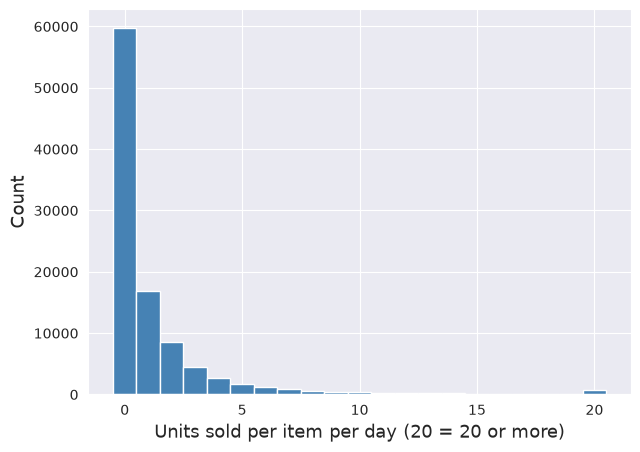

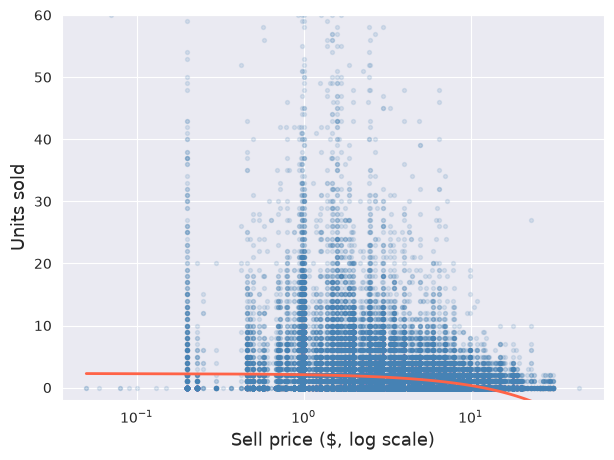

In [11]:
sns.set_style("darkgrid")

print(f"Share of observations with zero sales: {(df['sales'] == 0).mean():.1%}")
print(f"Mean: {df['sales'].mean():.2f} | Median: {df['sales'].median():.0f} | "
      f"99th percentile: {df['sales'].quantile(0.99):.0f} | Max: {df['sales'].max():.0f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(df['sales'].clip(upper=20), bins=np.arange(-0.5, 21.5, 1), color='steelblue')
ax.set_xlabel('Units sold per item per day (20 = 20 or more)', fontsize=13)
ax.set_ylabel('Count', fontsize=13)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['sell_price'], df['sales'], alpha=0.15, s=8, color='steelblue')
m = np.polyfit(df['sell_price'], df['sales'], 1)
x_line = np.linspace(df['sell_price'].min(), df['sell_price'].max(), 100)
ax.plot(x_line, np.polyval(m, x_line), color='tomato', linewidth=2)
ax.set_xscale('log')
ax.set_ylim(-2, 60)
ax.set_xlabel('Sell price ($, log scale)', fontsize=13)
ax.set_ylabel('Units sold', fontsize=13)
plt.show()

Recent sales should be strongly related to today's sales: an item that sold 10 units a day recently will probably sell around 10 today. The scatter plots below show each observation's sales against `roll28` (left) and the new `roll7` (right), with the 45-degree line where today's sales equal the recent average.


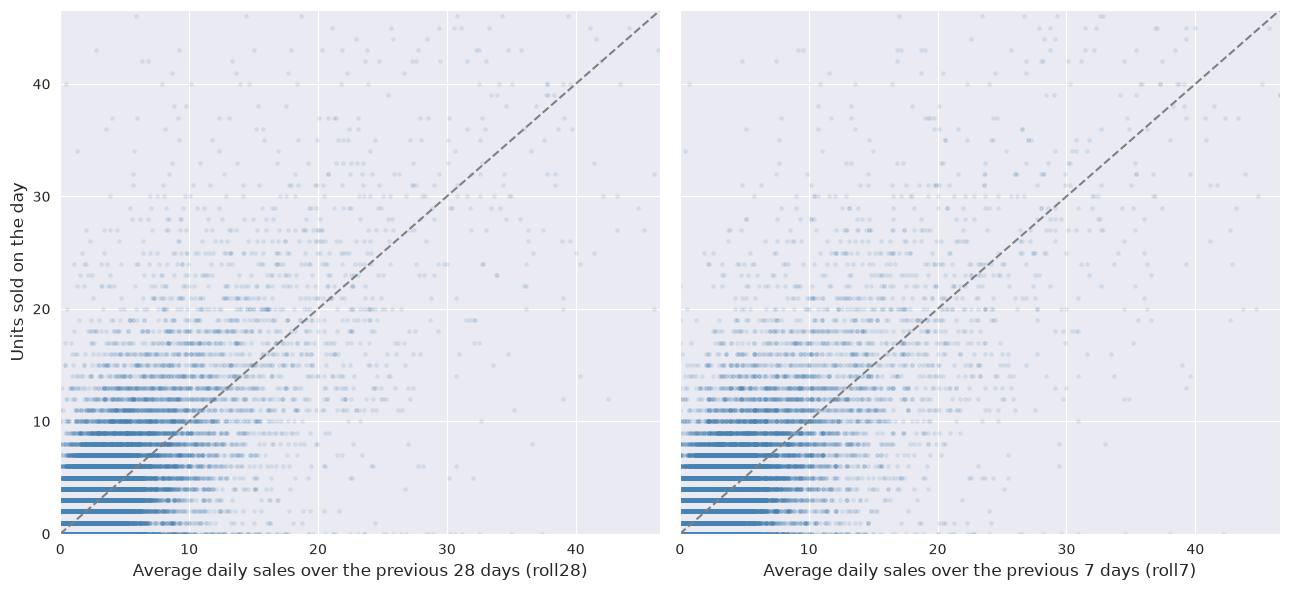

Correlation between roll28 and sales:  0.803
Correlation between roll7 and sales:   0.822
Correlation between roll28 and roll7:  0.951


In [12]:
sns.set_style("darkgrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
lim = np.percentile(np.r_[df['roll28'], df['roll7'], df['sales']], 99.9)

for ax, col, label in [(axes[0], 'roll28', 'previous 28 days (roll28)'),
                       (axes[1], 'roll7', 'previous 7 days (roll7)')]:
    ax.scatter(df[col], df['sales'], alpha=0.1, s=6, color='steelblue')
    ax.plot([0, lim], [0, lim], linestyle='--', color='grey', linewidth=1.5)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel(f'Average daily sales over the {label}', fontsize=12)
axes[0].set_ylabel('Units sold on the day', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Correlation between roll28 and sales:  {df['roll28'].corr(df['sales']):.3f}")
print(f"Correlation between roll7 and sales:   {df['roll7'].corr(df['sales']):.3f}")
print(f"Correlation between roll28 and roll7:  {df['roll28'].corr(df['roll7']):.3f}")


We next look at average daily sales across the levels of each categorical feature. These are **one-variable-at-a-time** comparisons: for example, the store differences partly reflect which categories each store sells, and the month differences partly reflect which events fall in each month. The regression will separate these effects.

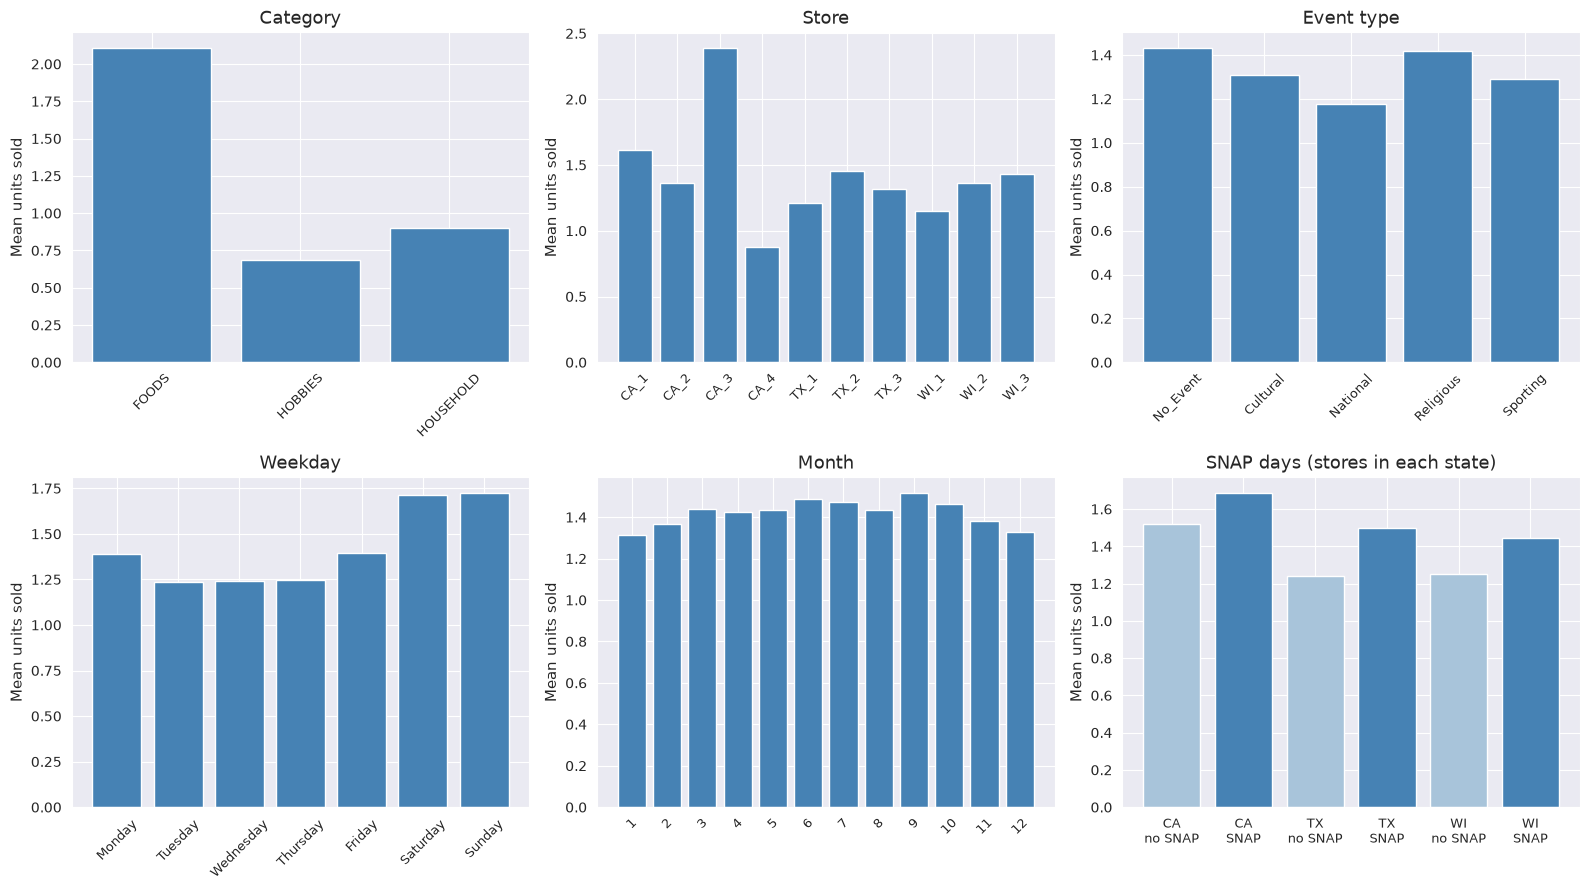

In [13]:
orders = {
    'cat_id': ['FOODS', 'HOBBIES', 'HOUSEHOLD'],
    'store_id': sorted(df['store_id'].unique()),
    'event_type': ['No_Event', 'Cultural', 'National', 'Religious', 'Sporting'],
    'weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    'month': list(range(1, 13)),
}
titles = {'cat_id': 'Category', 'store_id': 'Store', 'event_type': 'Event type',
          'weekday': 'Weekday', 'month': 'Month'}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (col, order) in zip(axes, orders.items()):
    means = df.groupby(col)['sales'].mean().reindex(order)
    ax.bar([str(v) for v in means.index], means.values, color='steelblue')
    ax.set_title(titles[col], fontsize=13)
    ax.set_ylabel('Mean units sold', fontsize=11)
    ax.tick_params(axis='x', rotation=45, labelsize=9)

# SNAP: compare each state's stores on SNAP vs non-SNAP days
snap_rows = []
for state in ['CA', 'TX', 'WI']:
    sub = df[df['store_id'].str.startswith(state)]
    for flag in [0, 1]:
        snap_rows.append((f"{state}\n{'SNAP' if flag else 'no SNAP'}",
                          sub.loc[sub[f'snap_{state}'] == flag, 'sales'].mean()))
axes[5].bar([r[0] for r in snap_rows], [r[1] for r in snap_rows],
            color=['#A8C4DA', 'steelblue'] * 3)
axes[5].set_title("SNAP days (stores in each state)", fontsize=13)
axes[5].set_ylabel('Mean units sold', fontsize=11)
axes[5].tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.show()

## Getting Started with Linear Regression

We begin by fitting an ordinary least squares (OLS) linear regression with all the features: `sell_price`, `roll28`, `roll7` and the one-hot indicators. sklearn's `LinearRegression` works directly on the sparse matrix.

We do **not** print a statsmodels table with standard errors and significance stars. statsmodels needs a dense matrix (over 5 GB here), and with item × store indicators the design is heavily rank deficient (see below), so most individual p-values would not be meaningful anyway. We report the OLS coefficients of the non-item features instead.

In [14]:
def ols_coefficient_table(model, feature_cols, hide_prefixes=('item_id_', 'item_store_')):
    coefs = pd.Series(model.coef_, index=feature_cols)
    hidden = coefs.index.str.startswith(hide_prefixes)
    print("=" * 60)
    print("Linear Regression Coefficients (non-item features)")
    print("=" * 60)
    print(f"{'const':<32}{model.intercept_:>10.4f}")
    for name, value in coefs[~hidden].items():
        print(f"{name:<32}{value:>10.4f}")
    print("=" * 60)
    for prefix in hide_prefixes:
        print(f"... {coefs.index.str.startswith(prefix).sum():,} '{prefix}*' coefficients not shown")
    print("=" * 60)

### Built-In Collinearities: Events, Items, Categories and Stores

Before reading the OLS output, note one feature of our design. Every event name belongs to exactly one event type: the Super Bowl is always `Sporting`, Christmas is always `Religious`, and so on. As a result, each `event_type` indicator is **exactly the sum** of the `event_name` indicators of that type. The design matrix is therefore **rank deficient**: OLS cannot tell how much of an event's effect to attribute to its name and how much to its type.

The cell below confirms this. OLS still produces predictions (statsmodels and sklearn both return the minimum-norm solution), and those predictions are unaffected, but the individual event coefficients and their p-values are **not meaningful** in the OLS table. The same thing happens with **items and categories**: every item belongs to exactly one category, so each `cat_id` indicator is the sum of the indicators of the items in that category.

The new **item × store** indicators add two more such relationships. Every item-store belongs to one item and one store, so each `item_id` indicator is the sum of the indicators of that item in the various stores, and each `store_id` indicator is the sum of the indicators of the items in that store. Once `item_store` is in the model, `item_id`, `store_id` and `cat_id` add no new information to OLS. We keep them, as requested, and let Ridge and LASSO decide how to share the effects.

In [15]:
# Each event name maps to one event type, each item to one category,
# and each item-store to one item and one store
checks = [('event_name', 'event_type'), ('item_id', 'cat_id'),
          ('item_store', 'item_id'), ('item_store', 'store_id')]
for child, parent in checks:
    sub = df if child != 'event_name' else df[df['event_name'] != 'No_Event']
    n_parents = sub.groupby(child)[parent].nunique()
    print(f"Every {child:<11} belongs to exactly one {parent:<11}: {bool((n_parents == 1).all())}")

item_cols = [c for c in feature_cols if c.startswith('item_id_')]
item_store_cols = [c for c in feature_cols if c.startswith('item_store_')]
print(f"\nThe {len(item_store_cols):,} item_store columns contain all the information in the "
      f"{len(item_cols):,} item_id, 9 store_id and 2 cat_id columns.")

Every event_name  belongs to exactly one event_type : True
Every item_id     belongs to exactly one cat_id     : True
Every item_store  belongs to exactly one item_id    : True
Every item_store  belongs to exactly one store_id   : True

The 28,146 item_store columns contain all the information in the 3,048 item_id, 9 store_id and 2 cat_id columns.


In [16]:
lr = LinearRegression().fit(X_train, y_train)

p_lr_tr = lr.predict(X_train)
p_lr_te = lr.predict(X_test)

ols_coefficient_table(lr, feature_cols)

r2_lr   = r2(p_lr_tr, y_train)
osr2_lr = osr2(p_lr_te, y_test, y_train.mean())
rmse_lr_tr = rmse(p_lr_tr, y_train)
rmse_lr_te = rmse(p_lr_te, y_test)
wrmsse_lr_te = wrmsse(p_lr_te, y_test, ids_test)
mae_lr_te = mae(p_lr_te, y_test)
wape_lr_te = wape(p_lr_te, y_test)

Linear Regression Coefficients (non-item features)
const                               0.2541
sell_price                         -0.0244
roll28                              0.1766
roll7                               0.7208
cat_id_HOBBIES                     -0.0971
cat_id_HOUSEHOLD                   -0.0696
store_id_CA_2                      -0.0488
store_id_CA_3                       0.0913
store_id_CA_4                      -0.1054
store_id_TX_1                      -0.0524
store_id_TX_2                      -0.0426
store_id_TX_3                      -0.0633
store_id_WI_1                      -0.0609
store_id_WI_2                      -0.0472
store_id_WI_3                       0.0006
event_name_Chanukah End            -0.1729
event_name_Christmas               -1.2557
event_name_Cinco De Mayo           -0.0222
event_name_ColumbusDay             -0.0552
event_name_Easter                   0.0582
event_name_Eid al-Fitr             -0.0008
event_name_EidAlAdha                0.0415
eve

In [17]:
print("Linear regression")
print(f"Training R²:    {r2_lr:.4f}")
print(f"Test OSR²:      {osr2_lr:.4f}")
print(f"Training RMSE:  {rmse_lr_tr:.4f}")
print(f"Test RMSE:      {rmse_lr_te:.4f}")
print(f"Test WRMSSE:    {wrmsse_lr_te:.4f}")
print(f"Test MAE:       {mae_lr_te:.4f}")
print(f"Test WAPE:      {wape_lr_te:.2%}")

Linear regression
Training R²:    0.7894
Test OSR²:      0.4588
Training RMSE:  1.9951
Test RMSE:      2.6590
Test WRMSSE:    0.7514
Test MAE:       1.2097
Test WAPE:      94.12%


# Regularization methods

**Regularization** adds a penalty for large coefficient values to the usual least-squares objective. This trades a small amount of in-sample fit for potentially better performance on new observations, and it also resolves the event name / event type collinearity: among all coefficient vectors that fit equally well, the penalty picks a unique one.

## Ridge Regression

**Ridge regression** adds a **squared penalty** on the coefficients. We fit Ridge over a wide range of $\lambda$ values, record the training and test performance, and plot the coefficients. As in the lecture, we temporarily use the test set to illustrate the effect of $\lambda$; we select $\lambda$ properly with **cross-validation** further below.

Note: the parameter $\lambda$ is implemented as `alpha` in sklearn.

### Regularization Is Scale-Dependent

Ridge and LASSO penalize the **size of the coefficients**, so the answer depends on the units of each feature. `sell_price` ranges from a few cents to over \$100, while an indicator for a rare event is 1 on only a fraction of a percent of days. We therefore standardize every feature (mean zero, standard deviation one) inside a `make_pipeline(StandardScaler(), ...)`, which refits the scaler on whatever training data it receives and keeps the test set and validation folds out of the calculation.

With a sparse matrix we use `StandardScaler(with_mean=False)`: subtracting the mean would turn every zero into a nonzero number and destroy the sparsity. The scaler only divides each column by its standard deviation, and the models fit the intercept as if the columns were centered, so the result is the same as full standardization.

Standardizing one-hot indicators is a modeling choice: it puts rare and common levels on an equal footing in the penalty, so a rare event is not penalized more heavily just because its indicator has a small variance. Each standardized coefficient measures the effect of a **one standard deviation** change in the feature.

In [18]:
# The features are on very different scales
scales = pd.Series(StandardScaler(with_mean=False).fit(X_train).scale_, index=feature_cols).sort_values()

print("Smallest standard deviations:")
print(scales.head(3).round(4).to_string())
print("\nLargest standard deviations:")
print(scales.tail(3).round(4).to_string())
print(f"\nRatio of largest to smallest: {scales.max() / scales.min():.0f}x")

Smallest standard deviations:
item_store_HOBBIES_1_130_WI_3      0.0035
item_store_HOBBIES_1_345_CA_1      0.0035
item_store_HOUSEHOLD_1_412_CA_1    0.0035

Largest standard deviations:
sell_price    3.3609
roll28        3.5582
roll7         3.7461

Ratio of largest to smallest: 1060x


With 80,000 training observations, the least-squares term of the objective is large, so the penalty only starts to bite for large values of $\lambda$. We therefore search a wider range than in the lecture. With over 31,000 features the LASSO fits take several seconds each, so we use 41 grid points for Ridge and 31 for LASSO in these illustrative paths.

In [19]:
# Generate a wide range of candidate regularization parameters.
# Larger values of lambda correspond to stronger regularization.
alphas_ridge_full = np.exp(np.linspace(18, -2, 41))
log_alphas_ridge_full = np.log(alphas_ridge_full)


def ridge_path_fit(alpha):
    # Standardize the features, then fit Ridge on the standardized features
    m = make_pipeline(StandardScaler(with_mean=False), Ridge(alpha=alpha)).fit(X_train, y_train)
    p_tr = m.predict(X_train)
    p_te = m.predict(X_test)
    return (m[-1].coef_, r2(p_tr, y_train), osr2(p_te, y_test, y_train.mean()),
            rmse(p_tr, y_train), rmse(p_te, y_test), wrmsse(p_te, y_test, ids_test),
            mae(p_te, y_test), wape(p_te, y_test))


# Fit a Ridge model for every value of lambda, in parallel (each fit is independent)
res = Parallel(n_jobs=N_JOBS)(delayed(ridge_path_fit)(a) for a in alphas_ridge_full)

# Coefficient paths (per standard deviation of each feature) and performance metrics
ridge_coefs_path = np.column_stack([r[0] for r in res])
r2_ridge_tr, osr2_ridge_te, rmse_ridge_tr, rmse_ridge_te, wrmsse_ridge_te, mae_ridge_te, wape_ridge_te = (
    np.array([r[j] for r in res]) for j in range(1, 8))


The figure below shows how the Ridge coefficients change as $\lambda$ increases. Each curve is one feature; the item and item × store indicators are drawn in light grey and all other features in color. When $\lambda$ is small, Ridge behaves like OLS; as $\lambda$ grows, the coefficients shrink smoothly toward zero.

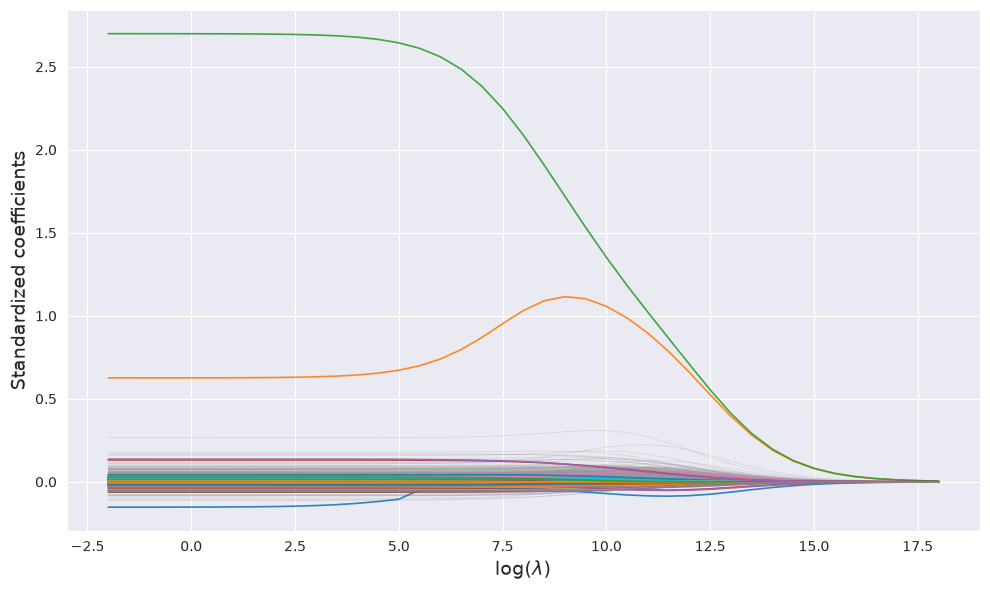

In [20]:
# Plot the Ridge coefficient path
sns.set_style("darkgrid")
plt.figure(figsize=(10, 6))

# Each curve corresponds to one predictor: item and item-store indicators in light grey,
# all other features in color
for j in range(k):
    is_item = feature_cols[j].startswith(('item_id_', 'item_store_'))
    plt.plot(
        log_alphas_ridge_full,
        ridge_coefs_path[j, :],
        linewidth=0.5 if is_item else 1.2,
        alpha=0.3 if is_item else 0.9,
        color='0.6' if is_item else None,
        zorder=1 if is_item else 2
    )

plt.xlabel("log($\\lambda$)", fontsize=14)
plt.ylabel("Standardized coefficients", fontsize=14)

plt.tight_layout()
plt.show()

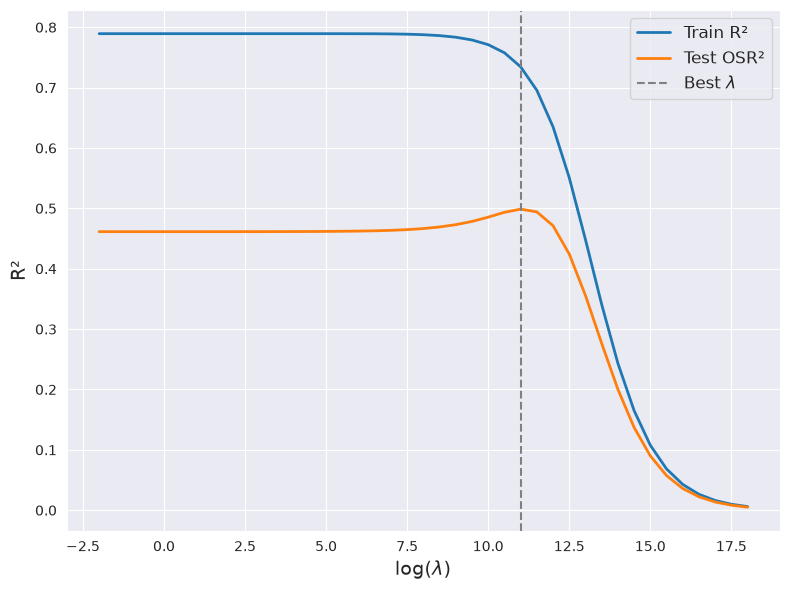

Best Ridge log(λ): 11.0000 (λ = 59874.1417)
Training R²:   0.7345
Test OSR²:     0.4988
Training RMSE: 2.2399
Test RMSE:     2.5589
Test WRMSSE:   0.7123
Test MAE:      1.1252
Test WAPE:     87.54%


In [21]:
# Find the value of lambda that maximizes the test OSR²
best_ridge_idx_full = int(np.argmax(osr2_ridge_te))
best_alpha_ridge_full = alphas_ridge_full[best_ridge_idx_full]

# Plot training and test performance as a function of lambda
sns.set_style("darkgrid")
plt.figure(figsize=(8, 6))

plt.plot(log_alphas_ridge_full, r2_ridge_tr, linewidth=2, label="Train R²")
plt.plot(log_alphas_ridge_full, osr2_ridge_te, linewidth=2, label="Test OSR²")

# Mark the best value of lambda
plt.axvline(
    np.log(best_alpha_ridge_full),
    linestyle="--",
    color="grey",
    linewidth=1.5,
    label="Best $\\lambda$"
)

plt.xlabel("log($\\lambda$)", fontsize=14)
plt.ylabel("R²", fontsize=14)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

# Display the performance of the selected model
print(f"Best Ridge log(λ): {np.log(best_alpha_ridge_full):.4f} (λ = {best_alpha_ridge_full:.4f})")
print(f"Training R²:   {r2_ridge_tr[best_ridge_idx_full]:.4f}")
print(f"Test OSR²:     {osr2_ridge_te[best_ridge_idx_full]:.4f}")
print(f"Training RMSE: {rmse_ridge_tr[best_ridge_idx_full]:.4f}")
print(f"Test RMSE:     {rmse_ridge_te[best_ridge_idx_full]:.4f}")
print(f"Test WRMSSE:   {wrmsse_ridge_te[best_ridge_idx_full]:.4f}")
print(f"Test MAE:      {mae_ridge_te[best_ridge_idx_full]:.4f}")
print(f"Test WAPE:     {wape_ridge_te[best_ridge_idx_full]:.2%}")

## LASSO Regression

**LASSO** penalizes the **absolute values** of the coefficients instead of their squares. As $\lambda$ increases, LASSO not only shrinks the coefficients but sets some of them **exactly to zero**, removing those features from the model. In our setting this is a natural way to ask which events, months or weekdays actually matter for sales.

In [22]:
# Create a wide range of candidate regularization parameters.
# Large lambda values impose stronger regularization.
alphas_lasso_full = np.exp(np.linspace(2, -5, 31))
log_alphas_lasso_full = np.log(alphas_lasso_full)

# Store the coefficient path and the performance metrics
lasso_coefs_path = np.zeros((k, len(alphas_lasso_full)))
r2_lasso_tr = np.zeros(len(alphas_lasso_full))
osr2_lasso_te = np.zeros(len(alphas_lasso_full))
rmse_lasso_tr = np.zeros(len(alphas_lasso_full))
rmse_lasso_te = np.zeros(len(alphas_lasso_full))
wrmsse_lasso_te = np.zeros(len(alphas_lasso_full))
mae_lasso_te = np.zeros(len(alphas_lasso_full))
wape_lasso_te = np.zeros(len(alphas_lasso_full))

# Fit a LASSO model for every value of lambda, standardizing as for Ridge.
# The lambda values run from large to small, and warm_start=True starts each fit
# from the previous solution, which makes the path much faster to compute.
m = make_pipeline(StandardScaler(with_mean=False), Lasso(max_iter=50000, warm_start=True))

for i, alpha in enumerate(alphas_lasso_full):

    m.set_params(lasso__alpha=alpha).fit(X_train, y_train)

    # Store the estimated coefficients
    lasso_coefs_path[:, i] = m[-1].coef_

    # Generate predictions on the training and test sets
    p_tr = m.predict(X_train)
    p_te = m.predict(X_test)

    # Compute training and test performance
    r2_lasso_tr[i] = r2(p_tr, y_train)
    osr2_lasso_te[i] = osr2(p_te, y_test, y_train.mean())
    rmse_lasso_tr[i] = rmse(p_tr, y_train)
    rmse_lasso_te[i] = rmse(p_te, y_test)
    wrmsse_lasso_te[i] = wrmsse(p_te, y_test, ids_test)
    mae_lasso_te[i] = mae(p_te, y_test)
    wape_lasso_te[i] = wape(p_te, y_test)

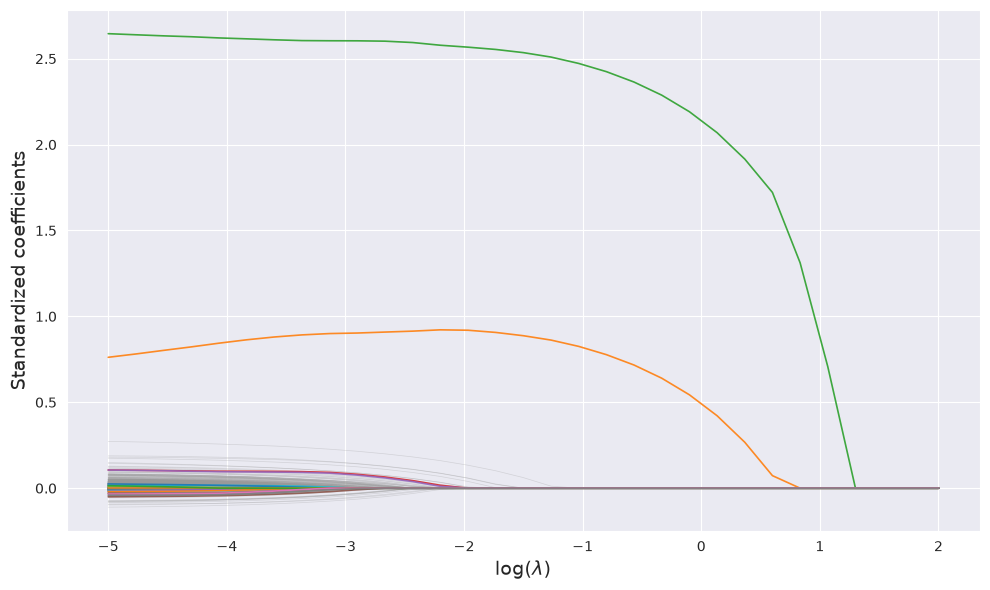

In [23]:
# Plot the LASSO coefficient path
sns.set_style("darkgrid")
plt.figure(figsize=(10, 6))

# Each curve corresponds to one predictor: item and item-store indicators in light grey,
# all other features in color
for j in range(k):
    is_item = feature_cols[j].startswith(('item_id_', 'item_store_'))
    plt.plot(
        log_alphas_lasso_full,
        lasso_coefs_path[j, :],
        linewidth=0.5 if is_item else 1.2,
        alpha=0.3 if is_item else 0.9,
        color='0.6' if is_item else None,
        zorder=1 if is_item else 2
    )

plt.xlabel("log($\\lambda$)", fontsize=14)
plt.ylabel("Standardized coefficients", fontsize=14)

plt.tight_layout()
plt.show()

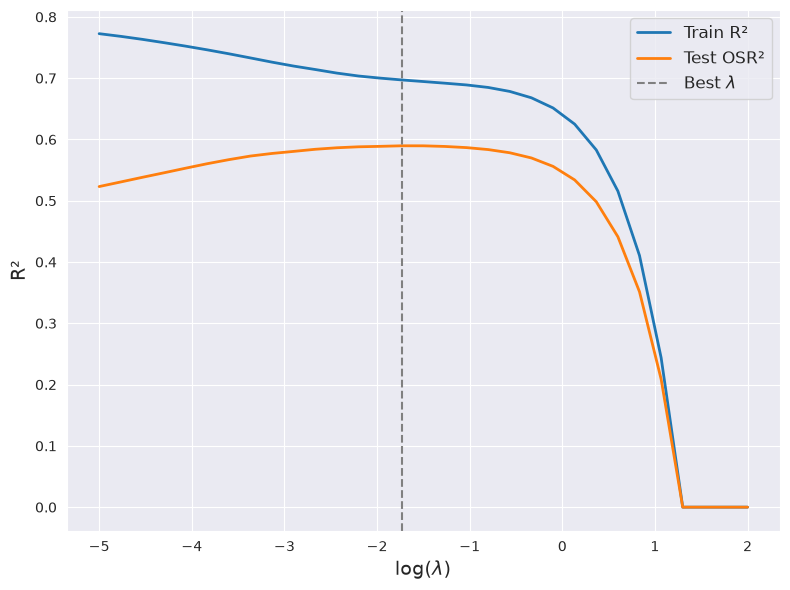

Best LASSO log(λ): -1.7333 (λ = 0.1767)
Training R²:   0.6971
Test OSR²:     0.5897
Training RMSE: 2.3926
Test RMSE:     2.3153
Test WRMSSE:   0.6278
Test MAE:      0.9804
Test WAPE:     76.27%
Features retained: 6 of 31262


In [24]:
# Find the value of lambda that maximizes the test OSR²
best_lasso_idx_full = int(np.argmax(osr2_lasso_te))
best_alpha_lasso_full = alphas_lasso_full[best_lasso_idx_full]

# Plot training and test performance as a function of lambda
sns.set_style("darkgrid")
plt.figure(figsize=(8, 6))

plt.plot(log_alphas_lasso_full, r2_lasso_tr, linewidth=2, label="Train R²")
plt.plot(log_alphas_lasso_full, osr2_lasso_te, linewidth=2, label="Test OSR²")

# Mark the best value of lambda
plt.axvline(
    np.log(best_alpha_lasso_full),
    linestyle="--",
    color="grey",
    linewidth=1.5,
    label="Best $\\lambda$"
)

plt.xlabel("log($\\lambda$)", fontsize=14)
plt.ylabel("R²", fontsize=14)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

# Display the performance of the selected model
print(f"Best LASSO log(λ): {np.log(best_alpha_lasso_full):.4f} (λ = {best_alpha_lasso_full:.4f})")
print(f"Training R²:   {r2_lasso_tr[best_lasso_idx_full]:.4f}")
print(f"Test OSR²:     {osr2_lasso_te[best_lasso_idx_full]:.4f}")
print(f"Training RMSE: {rmse_lasso_tr[best_lasso_idx_full]:.4f}")
print(f"Test RMSE:     {rmse_lasso_te[best_lasso_idx_full]:.4f}")
print(f"Test WRMSSE:   {wrmsse_lasso_te[best_lasso_idx_full]:.4f}")
print(f"Test MAE:      {mae_lasso_te[best_lasso_idx_full]:.4f}")
print(f"Test WAPE:     {wape_lasso_te[best_lasso_idx_full]:.2%}")
print(f"Features retained: {int(np.sum(lasso_coefs_path[:, best_lasso_idx_full] != 0))} of {k}")

### Out-of-sample performance (test-selected $\lambda$)

We compare OLS, Ridge and LASSO using the best $\lambda$ for each method on the test set. Remember that this comparison is **optimistic** for Ridge and LASSO, because the test set was used to pick $\lambda$. We correct this with cross-validation next.

In [25]:
# Compare the performance of the three models
summary_df = pd.DataFrame([
    {
        "Model": "Linear regression",
        "R²": round(r2_lr, 4),
        "OSR²": round(osr2_lr, 4),
        "RMSE (train)": round(rmse_lr_tr, 4),
        "RMSE (test)": round(rmse_lr_te, 4),
        "WRMSSE (test)": round(wrmsse_lr_te, 4),
        "MAE (test)": round(mae_lr_te, 4),
        "WAPE (test)": round(wape_lr_te, 4),
    },
    {
        "Model": "Ridge (best λ)",
        "R²": round(r2_ridge_tr[best_ridge_idx_full], 4),
        "OSR²": round(osr2_ridge_te[best_ridge_idx_full], 4),
        "RMSE (train)": round(rmse_ridge_tr[best_ridge_idx_full], 4),
        "RMSE (test)": round(rmse_ridge_te[best_ridge_idx_full], 4),
        "WRMSSE (test)": round(wrmsse_ridge_te[best_ridge_idx_full], 4),
        "MAE (test)": round(mae_ridge_te[best_ridge_idx_full], 4),
        "WAPE (test)": round(wape_ridge_te[best_ridge_idx_full], 4),
    },
    {
        "Model": "LASSO (best λ)",
        "R²": round(r2_lasso_tr[best_lasso_idx_full], 4),
        "OSR²": round(osr2_lasso_te[best_lasso_idx_full], 4),
        "RMSE (train)": round(rmse_lasso_tr[best_lasso_idx_full], 4),
        "RMSE (test)": round(rmse_lasso_te[best_lasso_idx_full], 4),
        "WRMSSE (test)": round(wrmsse_lasso_te[best_lasso_idx_full], 4),
        "MAE (test)": round(mae_lasso_te[best_lasso_idx_full], 4),
        "WAPE (test)": round(wape_lasso_te[best_lasso_idx_full], 4),
    },
])

display(summary_df.set_index("Model"))

,R²,OSR²,RMSE (train),RMSE (test),WRMSSE (test),MAE (test),WAPE (test)
Model,,,,,,,
Linear regression,0.7894,0.4588,1.9951,2.6590,0.7514,1.2097,0.9412
Ridge (best λ),0.7345,0.4988,2.2399,2.5589,0.7123,1.1252,0.8754
LASSO (best λ),0.6971,0.5897,2.3926,2.3153,0.6278,0.9804,0.7627


Here **regularization changes the result**. OLS overfits badly: its training R² is 0.789 but its test OSR² only 0.459, a gap of 0.33. The reason is the item × store indicators: there are 28,146 of them for 80,000 training observations, so each item-store coefficient is estimated from only about 3 observations and mostly fits noise. With the time split the damage is larger than with a random split, because those few observations are also months or years older than the test days.

The two methods react very differently:
- **LASSO** (test-selected $\lambda$) raises the test OSR² from 0.459 to **0.590** and lowers the WRMSSE from 0.751 to **0.628**, while keeping only 6 of the 31,262 features. It can drop the noisy indicators entirely and keep the informative `roll28` and `roll7`.
- **Ridge** helps only a little (OSR² 0.499, WRMSSE 0.712). It shrinks all standardized coefficients together, so it cannot shrink the 28,146 noisy indicators enough without also shrinking the recent-sales averages, the most useful features.

## Cross-Validation

Instead of using the test data to tune the model, we repeatedly split the **training set** into smaller training and validation sets. For each candidate value of $\lambda$, we fit the model on the training folds and evaluate it on the validation fold, average the validation performance across folds, and select the $\lambda$ that performs best on average. We then refit on the entire training set and evaluate once on the untouched test set.

We still select $\lambda$ by the average validation **OSR²**, as in Lecture 4, but we also record the validation **WRMSSE** of every fold so that we can report it for the selected $\lambda$.

We fix a random seed for reproducibility.

In [26]:
np.random.seed(144)

Cross-validation fits one model per candidate $\lambda$ **and** per fold. With over 31,000 features, we use a coarser grid of 21 values for Ridge and 15 for LASSO over the same ranges as above, with warm starts for LASSO. The grid is coarse, but the validation curves below are smooth enough that a finer grid would barely move the selected $\lambda$.

In [27]:
alphas_ridge = np.exp(np.linspace(18, -2, 21))
log_alphas_ridge = np.log(alphas_ridge)

alphas_lasso = np.exp(np.linspace(2, -5, 15))
log_alphas_lasso = np.log(alphas_lasso)

### Creating the Cross-Validation Folds

We use **10-fold cross-validation** within the training period: the training set is randomly divided into 10 folds of about 8,000 observations each; each model is trained on 9 folds and evaluated on the remaining one, until every fold has served as the validation set once.

In [28]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

### Cross-Validation for Ridge Regression

In [29]:
folds = list(kf.split(X_train))


def ridge_cv_fit(fold_i, a_i):
    tr_idx, val_idx = folds[fold_i]
    # Split the training data into a training fold and a validation fold
    Xtr, ytr = X_train[tr_idx], y_train.iloc[tr_idx]
    Xval, yval = X_train[val_idx], y_train.iloc[val_idx]
    # The pipeline refits the scaler on the 9 training folds only,
    # so the validation fold never influences the standardization.
    m = make_pipeline(StandardScaler(with_mean=False), Ridge(alpha=alphas_ridge[a_i])).fit(Xtr, ytr)
    p_val = m.predict(Xval)
    return osr2(p_val, yval, ytr.mean()), wrmsse(p_val, yval, ids_train.iloc[val_idx])


# Perform 10-fold cross-validation: all 10 x 21 fits run in parallel
tasks = [(f, a) for f in range(10) for a in range(len(alphas_ridge))]
res = Parallel(n_jobs=N_JOBS)(delayed(ridge_cv_fit)(f, a) for f, a in tasks)

# Validation OSR² and WRMSSE for each fold and each value of lambda
cv_osr2_ridge = np.zeros((10, len(alphas_ridge)))
cv_wrmsse_ridge = np.zeros((10, len(alphas_ridge)))
for (f, a), (o, w) in zip(tasks, res):
    cv_osr2_ridge[f, a], cv_wrmsse_ridge[f, a] = o, w

# Average the validation performance across the 10 folds
mean_cv_osr2 = cv_osr2_ridge.mean(axis=0)

# Select the lambda with the highest average validation OSR²
R2_CV = max(mean_cv_osr2)
best_alpha_cv = alphas_ridge[np.argmax(mean_cv_osr2)]
WRMSSE_CV = cv_wrmsse_ridge.mean(axis=0)[np.argmax(mean_cv_osr2)]

print(f"CV best log(λ): {np.log(best_alpha_cv):.2f} (λ = {best_alpha_cv:.4f})")

CV best log(λ): 11.00 (λ = 59874.1417)


### Cross-Validation for LASSO Regression

In [30]:
def lasso_cv_fold(fold_i):
    tr_idx, val_idx = folds[fold_i]
    # Split the training data into a training fold and a validation fold
    Xtr, ytr = X_train[tr_idx], y_train.iloc[tr_idx]
    Xval, yval = X_train[val_idx], y_train.iloc[val_idx]
    # As above, the pipeline standardizes using the training folds only.
    # A fresh model per fold, warm-started along the lambda grid within the fold.
    m = make_pipeline(StandardScaler(with_mean=False), Lasso(max_iter=50000, warm_start=True))
    osr, wr = np.zeros(len(alphas_lasso)), np.zeros(len(alphas_lasso))
    for a_i, alpha in enumerate(alphas_lasso):
        m.set_params(lasso__alpha=alpha).fit(Xtr, ytr)
        p_val = m.predict(Xval)
        osr[a_i] = osr2(p_val, yval, ytr.mean())
        wr[a_i] = wrmsse(p_val, yval, ids_train.iloc[val_idx])
    return osr, wr


# Perform 10-fold cross-validation: the 10 folds run in parallel
res = Parallel(n_jobs=min(N_JOBS, 10))(delayed(lasso_cv_fold)(f) for f in range(10))

# Validation OSR² and WRMSSE for each fold and each value of lambda
cv_osr2_lasso = np.vstack([r[0] for r in res])
cv_wrmsse_lasso = np.vstack([r[1] for r in res])

# Average the validation performance across the 10 folds
mean_cv_osr2_lasso = cv_osr2_lasso.mean(axis=0)

# Select the lambda with the highest average validation OSR²
R2_lasso_CV = max(mean_cv_osr2_lasso)
best_alpha_lasso_cv = alphas_lasso[np.argmax(mean_cv_osr2_lasso)]
WRMSSE_lasso_CV = cv_wrmsse_lasso.mean(axis=0)[np.argmax(mean_cv_osr2_lasso)]

print(f"LASSO CV best log(λ): {np.log(best_alpha_lasso_cv):.2f} (λ = {best_alpha_lasso_cv:.4f})")

LASSO CV best log(λ): -1.50 (λ = 0.2231)


### Selecting the Regularization Parameter

The figures show the **average validation OSR²** across the 10 folds for each $\lambda$, with the selected value marked by the dashed line.

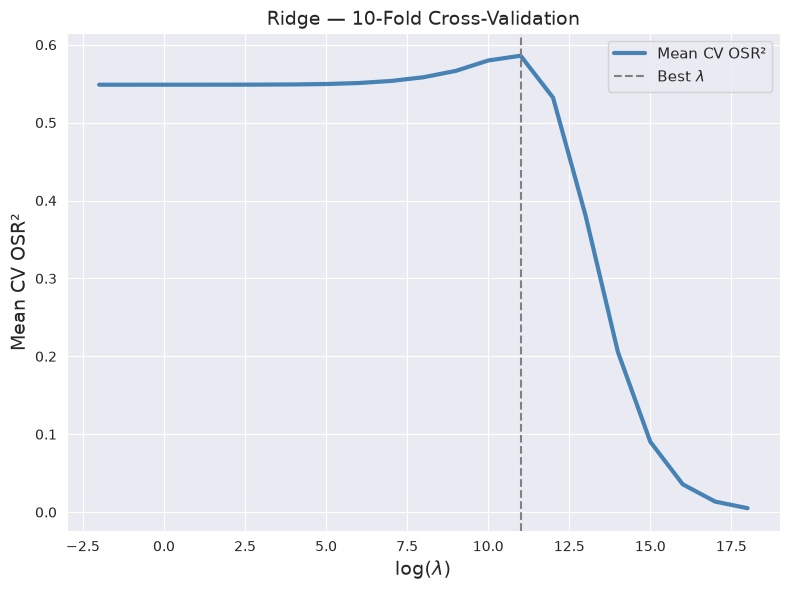

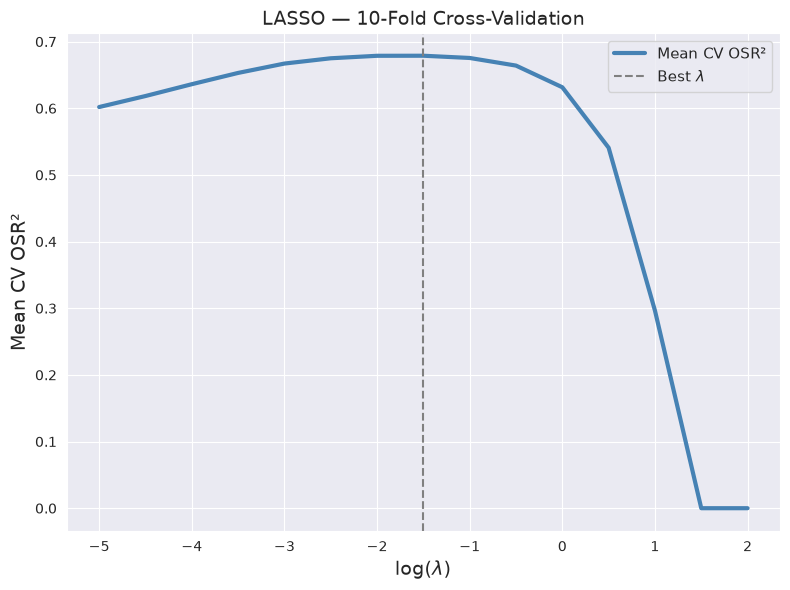

In [31]:
for name, log_alphas, mean_cv, best_alpha in [
    ("Ridge", log_alphas_ridge, mean_cv_osr2, best_alpha_cv),
    ("LASSO", log_alphas_lasso, mean_cv_osr2_lasso, best_alpha_lasso_cv),
]:
    sns.set_style("darkgrid")
    plt.figure(figsize=(8, 6))

    plt.plot(log_alphas, mean_cv, color="steelblue", linewidth=3, label="Mean CV OSR²")

    # Mark the best value of lambda
    plt.axvline(np.log(best_alpha), linestyle="--", color="grey", linewidth=1.5,
                label="Best $\\lambda$")

    plt.xlabel("log($\\lambda$)", fontsize=14)
    plt.ylabel("Mean CV OSR²", fontsize=14)
    plt.title(f"{name} — 10-Fold Cross-Validation", fontsize=14)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

## Out-of-Sample Assessment

We refit Ridge and LASSO on the **entire training set** with the $\lambda$ selected by cross-validation, and evaluate them on the held-out test set for the **first and only time**. The table compares cross-validation performance, in-sample fit and out-of-sample accuracy for the three models. For WRMSSE, lower is better.

In [32]:
# Ridge regression — use the best cross-validated lambda
ridge_final = make_pipeline(
    StandardScaler(with_mean=False),
    Ridge(alpha=best_alpha_cv)
).fit(X_train, y_train)

p_ridge_tr_final = ridge_final.predict(X_train)
p_ridge_te_final = ridge_final.predict(X_test)

r2_ridge_cv = r2(p_ridge_tr_final, y_train)
osr2_ridge_cv = osr2(p_ridge_te_final, y_test, y_train.mean())
rmse_ridge_cv_tr = rmse(p_ridge_tr_final, y_train)
rmse_ridge_cv_te = rmse(p_ridge_te_final, y_test)
wrmsse_ridge_cv_te = wrmsse(p_ridge_te_final, y_test, ids_test)
mae_ridge_cv_te = mae(p_ridge_te_final, y_test)
wape_ridge_cv_te = wape(p_ridge_te_final, y_test)


# LASSO — use the best cross-validated lambda
lasso_final = make_pipeline(
    StandardScaler(with_mean=False),
    Lasso(alpha=best_alpha_lasso_cv, max_iter=50000)
).fit(X_train, y_train)

p_lasso_tr_final = lasso_final.predict(X_train)
p_lasso_te_final = lasso_final.predict(X_test)

r2_lasso_cv = r2(p_lasso_tr_final, y_train)
osr2_lasso_cv = osr2(p_lasso_te_final, y_test, y_train.mean())
rmse_lasso_cv_tr = rmse(p_lasso_tr_final, y_train)
rmse_lasso_cv_te = rmse(p_lasso_te_final, y_test)
wrmsse_lasso_cv_te = wrmsse(p_lasso_te_final, y_test, ids_test)
mae_lasso_cv_te = mae(p_lasso_te_final, y_test)
wape_lasso_cv_te = wape(p_lasso_te_final, y_test)

# Count the predictors retained by LASSO
n_nonzero_lasso = int(np.sum(lasso_final[-1].coef_ != 0))


# Summarize the performance of all three models
final_summary = pd.DataFrame([
    {
        "Model": "Linear regression",
        "λ (CV)": "--",
        "R² CV": "--",
        "R² in-sample": round(r2_lr, 4),
        "R² out-of-sample": round(osr2_lr, 4),
        "RMSE in-sample": round(rmse_lr_tr, 4),
        "RMSE out-of-sample": round(rmse_lr_te, 4),
        "WRMSSE CV": "--",
        "WRMSSE out-of-sample": round(wrmsse_lr_te, 4),
        "MAE out-of-sample": round(mae_lr_te, 4),
        "WAPE out-of-sample": round(wape_lr_te, 4),
        "Features used": k,
    },
    {
        "Model": "Ridge regression",
        "λ (CV)": round(best_alpha_cv, 2),
        "R² CV": round(R2_CV, 4),
        "R² in-sample": round(r2_ridge_cv, 4),
        "R² out-of-sample": round(osr2_ridge_cv, 4),
        "RMSE in-sample": round(rmse_ridge_cv_tr, 4),
        "RMSE out-of-sample": round(rmse_ridge_cv_te, 4),
        "WRMSSE CV": round(WRMSSE_CV, 4),
        "WRMSSE out-of-sample": round(wrmsse_ridge_cv_te, 4),
        "MAE out-of-sample": round(mae_ridge_cv_te, 4),
        "WAPE out-of-sample": round(wape_ridge_cv_te, 4),
        "Features used": k,
    },
    {
        "Model": "LASSO",
        "λ (CV)": round(best_alpha_lasso_cv, 4),
        "R² CV": round(R2_lasso_CV, 4),
        "R² in-sample": round(r2_lasso_cv, 4),
        "R² out-of-sample": round(osr2_lasso_cv, 4),
        "RMSE in-sample": round(rmse_lasso_cv_tr, 4),
        "RMSE out-of-sample": round(rmse_lasso_cv_te, 4),
        "WRMSSE CV": round(WRMSSE_lasso_CV, 4),
        "WRMSSE out-of-sample": round(wrmsse_lasso_cv_te, 4),
        "MAE out-of-sample": round(mae_lasso_cv_te, 4),
        "WAPE out-of-sample": round(wape_lasso_cv_te, 4),
        "Features used": n_nonzero_lasso,
    },
])

display(final_summary.set_index("Model"))

,λ (CV),R² CV,R² in-sample,R² out-of-sample,RMSE in-sample,RMSE out-of-sample,WRMSSE CV,WRMSSE out-of-sample,MAE out-of-sample,WAPE out-of-sample,Features used
Model,,,,,,,,,,,
Linear regression,--,--,0.7894,0.4588,1.9951,2.6590,--,0.7514,1.2097,0.9412,31262
Ridge regression,59874.14,0.5859,0.7345,0.4988,2.2399,2.5589,0.667,0.7123,1.1252,0.8754,31262
LASSO,0.2231,0.6789,0.6945,0.5896,2.4030,2.3155,0.5764,0.6295,0.9846,0.7660,3


### Comparing the Estimated Coefficients

We compare the coefficients of the final Ridge and LASSO models (standardized, so magnitudes are comparable across features) with the OLS coefficients in original units. The table shows the **non-item features**; the thousands of `item_id` and `item_store` coefficients are summarized below it. A `--` marks a coefficient that LASSO has set exactly to zero.

In [33]:
coef_compare = pd.DataFrame({
    "Feature": feature_cols,
    "OLS (original units)": lr.coef_,
    "Ridge (standardized)": ridge_final[-1].coef_,
    "Lasso (standardized)": lasso_final[-1].coef_,
})
is_item_col = coef_compare["Feature"].str.startswith(("item_id_", "item_store_"))

for col in ["OLS (original units)", "Ridge (standardized)", "Lasso (standardized)"]:
    coef_compare[col] = coef_compare[col].apply(
        lambda x: "--" if np.isclose(x, 0) else f"{x:.4f}"
    )

pd.set_option("display.max_rows", 200)
display(coef_compare[~is_item_col].set_index("Feature"))

lasso_coefs = pd.Series(lasso_final[-1].coef_, index=feature_cols)
groups = {"sell_price / roll28 / roll7": lasso_coefs.index.isin(num_features)}
for c in cat_features:
    groups[c] = lasso_coefs.index.str.startswith(c + "_")

print(f"\nPredictors retained by LASSO: {n_nonzero_lasso:,} out of {k:,}")
for name, mask in groups.items():
    print(f"  {name:<26} {int((lasso_coefs[mask] != 0).sum()):>5,} of {int(mask.sum()):>5,}")

,OLS (original units),Ridge (standardized),Lasso (standardized)
Feature,,,
sell_price,-0.0244,-0.0846,--
roll28,0.1766,0.8955,0.8875
roll7,0.7208,1.0215,2.5353
cat_id_HOBBIES,-0.0971,-0.0491,--
cat_id_HOUSEHOLD,-0.0696,-0.0510,--
store_id_CA_2,-0.0488,-0.0068,--
store_id_CA_3,0.0913,0.0629,--
store_id_CA_4,-0.1054,-0.0335,--
store_id_TX_1,-0.0524,-0.0114,--



Predictors retained by LASSO: 3 out of 31,262
  sell_price / roll28 / roll7     2 of     3
  item_store                     1 of 28,146
  item_id                        0 of 3,048
  cat_id                         0 of     2
  store_id                       0 of     9
  event_name                     0 of    30
  event_type                     0 of     4
  snap_CA                        0 of     1
  snap_TX                        0 of     1
  snap_WI                        0 of     1
  month                          0 of    11
  weekday                        0 of     6


The chart ranks the features LASSO kept by the size of their standardized coefficient, so we can see which ones carry the prediction.

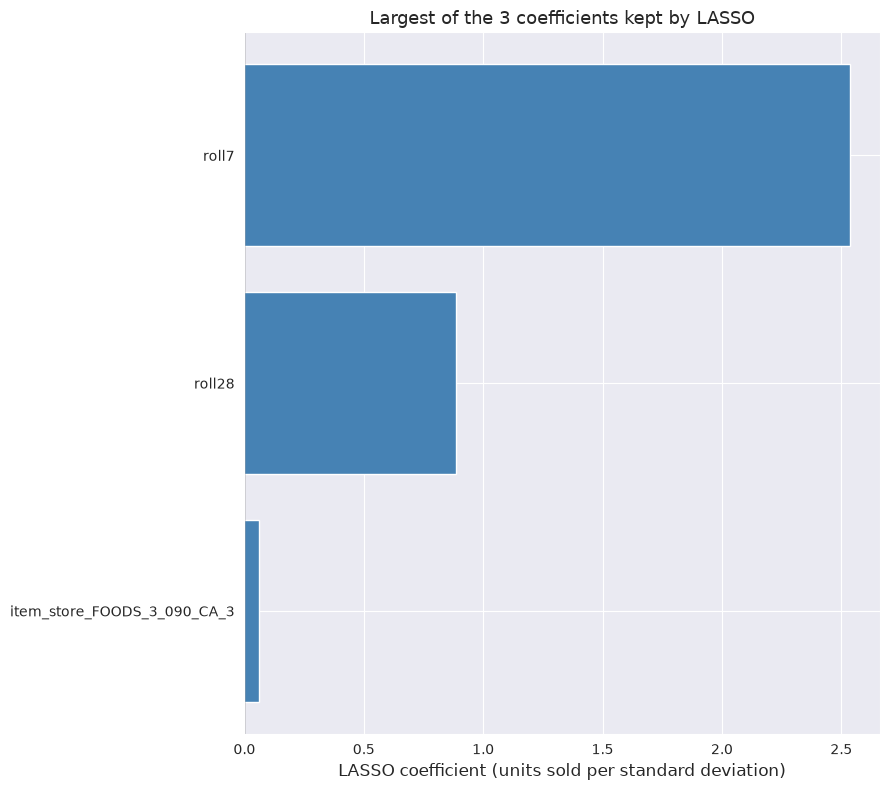

In [34]:
kept = lasso_coefs[lasso_coefs != 0]
top = kept.reindex(kept.abs().sort_values(ascending=False).index).head(20)[::-1]

sns.set_style("darkgrid")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=np.where(top.values > 0, 'steelblue', 'tomato'))
ax.axvline(0, color='0.3', linewidth=1)
ax.set_xlabel('LASSO coefficient (units sold per standard deviation)', fontsize=12)
ax.set_title(f'Largest of the {len(kept):,} coefficients kept by LASSO', fontsize=13)
plt.tight_layout()
plt.show()

### Which Features Help?

To see what each feature contributes, we refit OLS and LASSO (with the $\lambda$ selected above) on several feature sets, all using the same training and test sets. We start from the requested features plus `item_id`, add the recent-sales averages one at a time and together, then add the item × store indicators.


In [35]:
base_cols = [i for i, c in enumerate(feature_cols)
             if c not in ('roll28', 'roll7') and not c.startswith('item_store_')]
store_cols = [i for i, c in enumerate(feature_cols) if c.startswith('item_store_')]
roll28_col = [feature_cols.index('roll28')]
roll7_col = [feature_cols.index('roll7')]

feature_sets = {
    "Requested features + item_id": base_cols,
    "+ roll28": base_cols + roll28_col,
    "+ roll7": base_cols + roll7_col,
    "+ roll28 + roll7": base_cols + roll28_col + roll7_col,
    "+ item_store + roll28": base_cols + store_cols + roll28_col,
    "+ item_store + roll28 + roll7 (all features)": base_cols + store_cols + roll28_col + roll7_col,
}


def ablation_row(name, cols):
    Xtr_s, Xte_s = X_train[:, cols], X_test[:, cols]
    ols_s = LinearRegression().fit(Xtr_s, y_train)
    lasso_s = make_pipeline(StandardScaler(with_mean=False),
                            Lasso(alpha=best_alpha_lasso_cv, max_iter=50000)).fit(Xtr_s, y_train)
    p_ols_s, p_lasso_s = ols_s.predict(Xte_s), lasso_s.predict(Xte_s)
    return {
        "Feature set": name,
        "Features": len(cols),
        "OLS R² in-sample": round(r2(ols_s.predict(Xtr_s), y_train), 4),
        "OLS R² out-of-sample": round(osr2(p_ols_s, y_test, y_train.mean()), 4),
        "OLS WRMSSE": round(wrmsse(p_ols_s, y_test, ids_test), 4),
        "OLS MAE": round(mae(p_ols_s, y_test), 4),
        "OLS WAPE": round(wape(p_ols_s, y_test), 4),
        "LASSO R² out-of-sample": round(osr2(p_lasso_s, y_test, y_train.mean()), 4),
        "LASSO WRMSSE": round(wrmsse(p_lasso_s, y_test, ids_test), 4),
        "LASSO MAE": round(mae(p_lasso_s, y_test), 4),
        "LASSO WAPE": round(wape(p_lasso_s, y_test), 4),
        "LASSO features kept": int((lasso_s[-1].coef_ != 0).sum()),
    }


# The six feature sets are fit in parallel
rows = Parallel(n_jobs=min(N_JOBS, len(feature_sets)))(
    delayed(ablation_row)(name, cols) for name, cols in feature_sets.items())

ablation = pd.DataFrame(rows).set_index("Feature set")
display(ablation)

,Features,OLS R² in-sample,OLS R² out-of-sample,OLS WRMSSE,OLS MAE,OLS WAPE,LASSO R² out-of-sample,LASSO WRMSSE,LASSO MAE,LASSO WAPE,LASSO features kept
Feature set,,,,,,,,,,,
Requested features + item_id,3114,0.4202,0.2803,0.8550,1.3342,1.0380,0.1481,0.9756,1.6188,1.2595,29
+ roll28,3115,0.6758,0.5282,0.6729,1.0520,0.8185,0.5524,0.6541,1.0093,0.7852,1
+ roll7,3115,0.7060,0.5688,0.6577,1.0408,0.8098,0.5872,0.6334,0.9968,0.7755,1
+ roll28 + roll7,3116,0.7096,0.5701,0.6515,1.0298,0.8012,0.5898,0.6291,0.9835,0.7652,2
+ item_store + roll28,31261,0.7633,0.4013,0.7696,1.2269,0.9546,0.5523,0.6546,1.0106,0.7863,3
+ item_store + roll28 + roll7 (all features),31262,0.7894,0.4588,0.7514,1.2097,0.9412,0.5896,0.6295,0.9846,0.7660,3


The table separates the contributions of the features. Remember that higher OSR² and **lower** WRMSSE are better.

- **Recent sales history is by far the most valuable information.** Adding `roll28` alone to the requested features plus `item_id` lifts the OLS test OSR² from 0.28 to **0.53** and cuts the WRMSSE from 0.855 to 0.673, with a single extra column.
- **On later days, `roll7` is the more informative average.** Added alone, `roll7` reaches a test OSR² of **0.569** (WRMSSE 0.658) and `roll28` 0.528 (WRMSSE 0.673). When the model is frozen and the test days lie up to a year ahead, the most recent week tracks the drift in each item's sales better than the last month.
- **The two averages together are only slightly better than `roll7` alone.** With both, OLS reaches 0.570 (WRMSSE 0.652), the best OLS feature set in the table. In the full OLS model the weights are 0.18 on `roll28` and 0.72 on `roll7`.
- **`item_store` hurts OLS badly.** Adding the 28,146 item-store indicators to the two averages lowers the OLS OSR² from 0.570 to 0.459 and raises its WRMSSE from 0.652 to 0.751: each indicator is estimated from about 3 older training days, and 14% of the test item-stores never appear in training at all.
- **LASSO protects against this.** With all features, LASSO keeps only 3 of them (`roll28`, `roll7` and one item-store indicator) and scores 0.590 (WRMSSE 0.630), the same as LASSO on the two averages alone and better than any OLS feature set. The item-store indicators add nothing out of sample.

### Where the Models Go Wrong

Each panel below plots every test observation, with actual sales on the horizontal axis and predicted sales on the vertical axis. A perfect model would put every point on the dashed 45-degree line. Thanks to `roll28` and `roll7`, the predictions follow the actual sales closely, including for the best-selling items. The busiest days are still underpredicted, by about 3.7 to 5.0 units on the top 5% of days: `roll7` reacts faster than `roll28`, but a one-day spike is still invisible in any average of the past.


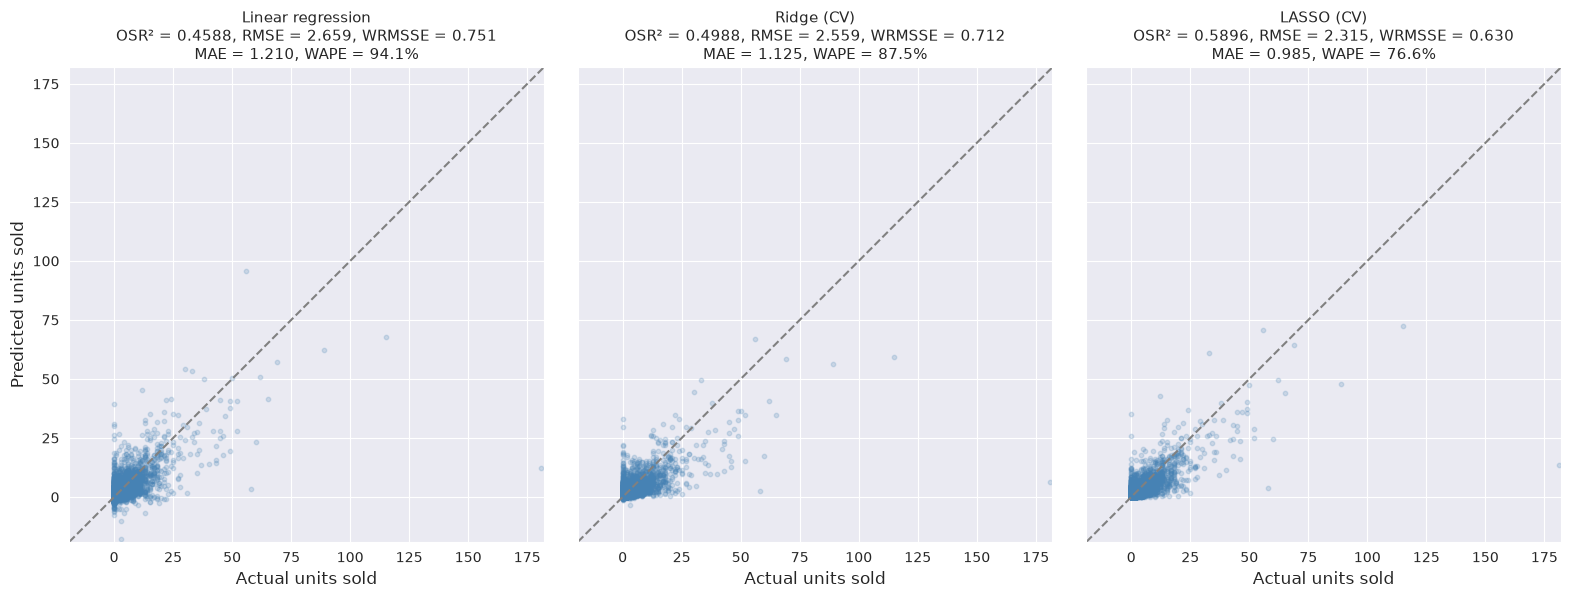

Mean prediction error, in units (negative = underprediction)
Model                 Zero-sales days   Top 5% days   All others
Linear regression                0.52         -3.70        -0.37
Ridge (CV)                       0.74         -4.95        -0.39
LASSO (CV)                       0.58         -4.03        -0.39


In [36]:
models = [
    ("Linear regression", p_lr_te, osr2_lr, rmse_lr_te, wrmsse_lr_te),
    ("Ridge (CV)", p_ridge_te_final, osr2_ridge_cv, rmse_ridge_cv_te, wrmsse_ridge_cv_te),
    ("LASSO (CV)", p_lasso_te_final, osr2_lasso_cv, rmse_lasso_cv_te, wrmsse_lasso_cv_te),
]

lo = min(y_test.min(), min(p.min() for _, p, _, _, _ in models)) - 1
hi = max(y_test.max(), max(p.max() for _, p, _, _, _ in models)) + 1

sns.set_style("darkgrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)

for ax, (name, pred, osr2_val, rmse_val, wrmsse_val) in zip(axes, models):
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="grey", linewidth=1.5)
    ax.scatter(y_test, pred, alpha=0.2, s=10, color="steelblue")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel("Actual units sold", fontsize=12)
    ax.set_title(f"{name}\nOSR² = {osr2_val:.4f}, RMSE = {rmse_val:.3f}, WRMSSE = {wrmsse_val:.3f}\n"
                 f"MAE = {mae(pred, y_test):.3f}, WAPE = {wape(pred, y_test):.1%}",
                 fontsize=11)

axes[0].set_ylabel("Predicted units sold", fontsize=12)
plt.tight_layout()
plt.show()

# Compare the errors on the zero-sales days and on the high-sales days
is_zero = y_test == 0
is_top = y_test >= y_test.quantile(0.95)

print("Mean prediction error, in units (negative = underprediction)")
print(f"{'Model':<20}{'Zero-sales days':>17}{'Top 5% days':>14}{'All others':>13}")
for name, pred, _, _, _ in models:
    err = pd.Series(np.asarray(pred) - y_test.values, index=y_test.index)
    print(f"{name:<20}{err[is_zero].mean():>17.2f}{err[is_top].mean():>14.2f}"
          f"{err[~is_zero & ~is_top].mean():>13.2f}")

### What the Error Is Worth

Finally, we put the test RMSE on a concrete scale. We compare a model that ignores every feature and always predicts the training mean, the OLS model, and the final cross-validated Ridge model.

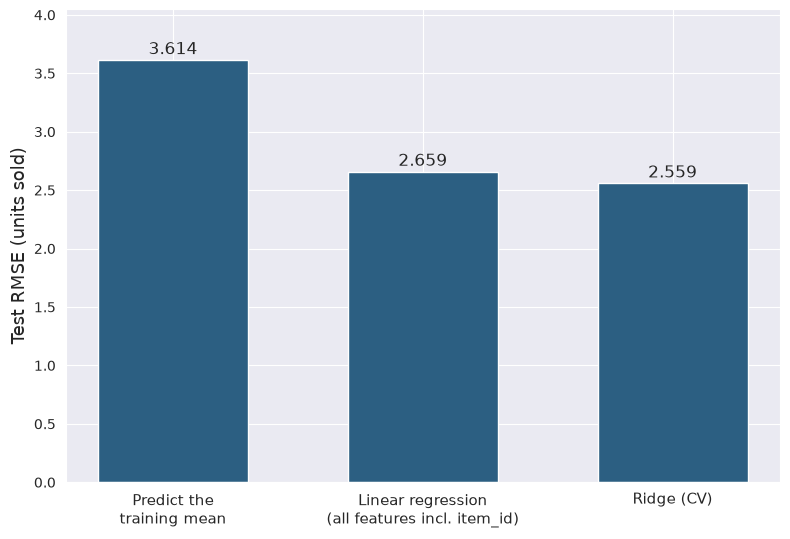

The features cut the error of the training-mean model by 26.4%  (3.614 -> 2.659 units)
Regularization + CV changed the OLS error by a further 3.76%  (2.659 -> 2.559 units)
Mean daily sales in the test set: 1.29 units


In [37]:
p_baseline_te = np.full(len(y_test), y_train.mean())
rmse_baseline_te = rmse(p_baseline_te, y_test)

gain_features = rmse_baseline_te - rmse_lr_te
gain_selection = rmse_lr_te - rmse_ridge_cv_te

pct_features = 100 * gain_features / rmse_baseline_te
pct_selection = 100 * gain_selection / rmse_lr_te

DARK = "#2C5F82"

sns.set_style("darkgrid")
fig, ax = plt.subplots(figsize=(8, 5.5))
labels = ["Predict the\ntraining mean", "Linear regression\n(all features incl. item_id)", "Ridge (CV)"]
values = [rmse_baseline_te, rmse_lr_te, rmse_ridge_cv_te]
ax.bar(range(3), values, width=0.6, color=DARK)
for x, v in enumerate(values):
    ax.text(x, v + 0.05, f"{v:.3f}", ha="center", fontsize=12, color="0.15")
ax.set_xticks(range(3))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel("Test RMSE (units sold)", fontsize=13)
ax.set_ylim(0, rmse_baseline_te * 1.12)
plt.tight_layout()
plt.show()

print(f"The features cut the error of the training-mean model by "
      f"{pct_features:.1f}%  ({rmse_baseline_te:.3f} -> {rmse_lr_te:.3f} units)")
print(f"Regularization + CV changed the OLS error by a further "
      f"{pct_selection:.2f}%  ({rmse_lr_te:.3f} -> {rmse_ridge_cv_te:.3f} units)")
print(f"Mean daily sales in the test set: {y_test.mean():.2f} units")

## Comparison with the Original Model

The table sets the out-of-sample results of this notebook beside the original model, which used only the 10 requested features on all items (numbers copied from that notebook). This notebook covers **the same population as the original model**: all 30,490 series, with about 60% zero-sales days. The test RMSE falls from 4.37 to 2.32 units and the OSR² rises from 0.046 to 0.590. Note that the original model was evaluated on a **random** split, which is easier than the time split used here, so the improvement is if anything understated. The original notebook did not compute the WRMSSE, MAE or WAPE.

In [38]:
original = pd.DataFrame({
    "Model": ["Linear regression", "Ridge regression", "LASSO"],
    "R² out-of-sample": [0.0465, 0.0464, 0.0462],
    "RMSE out-of-sample": [4.3669, 4.3672, 4.3676],
}).set_index("Model")

final = final_summary.set_index("Model")[["R² out-of-sample", "RMSE out-of-sample", "WRMSSE out-of-sample",
                                          "MAE out-of-sample", "WAPE out-of-sample"]]

comparison = pd.concat({"Original model (10 requested features, all items)": original,
                        "Final model (this notebook)": final}, axis=1)
display(comparison)


Original model (10 requested features, all items)  \
                                                   R² out-of-sample   
Model                                                                 
Linear regression                                            0.0465   
Ridge regression                                             0.0464   
LASSO                                                        0.0462   

                                     Final model (this notebook)  \
                  RMSE out-of-sample            R² out-of-sample   
Model                                                              
Linear regression             4.3669                      0.4588   
Ridge regression              4.3672                      0.4988   
LASSO                         4.3676                      0.5896   

                                                                             \
                  RMSE out-of-sample WRMSSE out-of-sample MAE out-of-sample   
Model                                                                         
Linear regression             2.6590               0.7514            1.2097   
Ridge regression              2.5589               0.7123            1.1252   
LASSO                         2.3155               0.6295            0.9846   

                                      
                  WAPE out-of-sample  
Model                                 
Linear regression             0.9412  
Ridge regression              0.8754  
LASSO                         0.7660

### How Do We Compare with Simple Forecasts?

A forecasting model is only useful if it beats the simple rules a store manager could apply without any model. We compare the regression models with four of them, each of which uses a single number per observation:

- **Series mean**: the average sales of the same item-store series in the training set;
- **Same as yesterday**: the sales of the previous day, the naive forecast that defines the WRMSSE scale;
- **28-day average**: predict `roll28` itself;
- **7-day average**: predict `roll7` itself.

Note that "same as yesterday" assumes the forecast is made the evening before, whereas the models only use averages that end the day before as well; none of them uses information from the forecast day.


In [39]:
# Average sales of each item-store series in the training set
series_mean = y_train.groupby(ids_train.values).mean()

# Series not seen in training fall back to the overall training mean
p_series_te = ids_test.map(series_mean).fillna(y_train.mean()).to_numpy()

benchmarks = [
    ("Linear regression (all features)", p_lr_te),
    ("Ridge (CV, all features)", p_ridge_te_final),
    ("LASSO (CV, all features)", p_lasso_te_final),
    ("Series mean (item-store identity only)", p_series_te),
    ("Same as yesterday (lag1)", df['lag1'].iloc[test_idx].to_numpy()),
    ("28-day average (roll28)", df['roll28'].iloc[test_idx].to_numpy()),
    ("7-day average (roll7)", df['roll7'].iloc[test_idx].to_numpy()),
]

print(f"Test observations whose series appears in the training set: {ids_test.isin(series_mean.index).mean():.1%}")
print()
print(f"{'Model':<45}{'OSR²':>8}{'RMSE':>9}{'WRMSSE':>9}{'MAE':>8}{'WAPE':>8}")
for name, pred in benchmarks:
    print(f"{name:<45}{osr2(pred, y_test, y_train.mean()):>8.4f}{rmse(pred, y_test):>9.3f}"
          f"{wrmsse(pred, y_test, ids_test):>9.4f}{mae(pred, y_test):>8.3f}{wape(pred, y_test):>8.1%}")


Test observations whose series appears in the training set: 86.2%

Model                                            OSR²     RMSE   WRMSSE     MAE    WAPE
Linear regression (all features)               0.4588    2.659   0.7514   1.210   94.1%
Ridge (CV, all features)                       0.4988    2.559   0.7123   1.125   87.5%
LASSO (CV, all features)                       0.5896    2.315   0.6295   0.985   76.6%
Series mean (item-store identity only)         0.1767    3.280   0.8917   1.391  108.2%
Same as yesterday (lag1)                       0.5065    2.539   0.7174   1.094   85.1%
28-day average (roll28)                        0.5523    2.418   0.6425   0.978   76.1%


7-day average (roll7)                          0.5881    2.320   0.6200   0.959   74.6%


## Takeaways

**Recent sales history turns a weak model into a useful one, also when predicting later days.** The original model, with only the 10 requested features, explained about 5% of the variation in daily sales. Trained on the first 80% of the days (to 2015-04-29) and tested on the last 389 days, the cross-validated LASSO with item identity and the 7- and 28-day sales averages reaches a test OSR² of **0.590** on all 30,490 series. Almost all of the gain comes from the two averages: they take OLS on the requested features plus `item_id` from 0.28 to 0.57. Under the time split `roll7` is the more useful of the two (OSR² 0.569 alone vs 0.528 for `roll28`), because the most recent week follows the drift in sales better.

**WRMSSE gives a business-weighted view of accuracy.** With scale and weights from the training period, the naive "same as yesterday" forecast scores 0.717, the training mean 1.050, and our best model (cross-validated LASSO) **0.630**, about 12% below the naive rule. Its cross-validated WRMSSE (0.576) is lower than the test value: validation folds are drawn from the same years as the training data, while the test days lie after them.

**MAE and WAPE tell the same story, in units.** The cross-validated LASSO misses by **0.985 units** per item-store-day on average (MAE), and its total absolute error is **76.6% of the units sold** (WAPE), against 1.21 units and 94.1% for OLS and 1.09 units and 85.1% for the "same as yesterday" rule. A WAPE this high is typical for daily item-store forecasts of slow sellers: the average test day sells only 1.3 units and most days sell nothing, so even a good forecast of the expected sales misses most individual days by about one unit.

**The simple averages are as good as the models.** The raw 7-day average alone scores OSR² 0.588, WRMSSE **0.620**, MAE 0.959 and WAPE 74.6%: practically the same OSR² as the cross-validated LASSO (0.590) and better on the other three measures. With most series selling only a few units a week, recent sales carry nearly all the predictable signal; the calendar, price and identity features add little on top, and a model frozen on 2015-04-29 cannot adapt them to later changes.

**Regularization matters even more with a time split.** OLS overfits the 28,146 item-store indicators (training R² 0.789 vs test OSR² 0.459). Cross-validated **LASSO** keeps only **3 of the 31,262 features** (`roll28`, `roll7` and one item-store indicator) and is the best of the three models on every test measure: OSR² 0.590, RMSE 2.32, WRMSSE 0.630. Ridge improves on OLS only slightly (OSR² 0.499, WRMSSE 0.712).

**Best model.** Cross-validated LASSO with all features (OSR² 0.590, RMSE 2.32, WRMSSE 0.630, MAE 0.985, WAPE 76.6%), or equivalently LASSO on the requested features, `item_id`, `roll28` and `roll7` (OSR² 0.590, WRMSSE 0.629). It cuts the test RMSE of the "predict the training mean" model by 36%, from 3.61 to 2.32 units.

**Time split vs. the earlier random split.** With a random 80/20 split of the same sample, the cross-validated LASSO scored OSR² 0.644 and WRMSSE 0.585 (naive rule 0.70), and OLS 0.540. Testing on later days lowers the OSR² by about 0.05 and widens the gap between OLS and LASSO. The time split is the honest one for forecasting: it only uses information available on 2015-04-29 to fit the model.

**Comparison with TimesFM.** The time split is now the same as in the TimesFM notebooks. TimesFM V3 reaches a test OSR² of 0.642 (MAE 0.988, WAPE 75.5%) on all 11.8 million test series-days while forecasting 1 to 28 days ahead, and 0.67 for 1 to 7 days ahead. The regression's 0.590 is a **one-day-ahead** forecast on a 20,000-day sample, so TimesFM is clearly more accurate on a harder task; MAE and WAPE are about the same. The WRMSSE values are not comparable: TimesFM's is the official 12-level, 28-day version.

**What remains.** The models still underpredict the busiest days by about 4 to 5 units, because any average of past days misses one-day spikes. Natural next steps are yesterday's sales and the sales of the same weekday a week earlier, a log or Poisson target to reduce negative predictions and handle the many zero-sales days, price changes relative to the item's usual price to capture promotions, refitting the model as new data arrive instead of freezing it, and selecting $\lambda$ by cross-validated WRMSSE instead of OSR².